# TENSORIX — Dolly 15k Instruction Fine-Tuning of the **Distilled** Student (SHORT tier)

**Project:** TENSORIX: Distilling Knowledge into a Small Language Model (AFML)
**Task:** repeat the finished baseline Dolly SFT experiment (`sft_dolly_baseline_v3`) on the knowledge-distilled student, with **identical** data, split, prompt format and training settings, and compare the instruction-tuned models.

## 1. Project overview and instructions

### What this notebook does, and why it is set up this way
* The README requires that the baseline and the best distilled model get instruction fine-tuning with identical settings. The baseline run is done (`sft_dolly_baseline_v3`, started from `baseline_full`). This notebook does the distilled side.
* **Which distilled checkpoint?** Temperature sweep (SHORT tier, 5,000 steps) found T=2 best. The README also plans a FULL-tier run `kd_full_T2` (20,000 steps), but **that checkpoint does not exist** on Drive or in the repository as of 11 Nov 2026 (checked). The team decided to fine-tune the available SHORT-tier checkpoint `kd_short_T2` and to label it as such.
* **Fair pairing.** `baseline_full` saw 4x more pretraining tokens than `kd_short_T2`, so `sft_dolly_baseline_v3` vs an SFT of `kd_short_T2` would mix the effect of distillation with the effect of longer pretraining. This notebook therefore runs **two** experiments with the same settings, one after the other:

| `EXPERIMENT` | start checkpoint | new run folder | purpose |
|---|---|---|---|
| `"kd_short_T2"` | `kd_short_T2/best.pt` (distilled, SHORT tier) | `sft_dolly_kd_short_T2_v1` | **the required distilled-model SFT** |
| `"baseline_short"` | `baseline_short/best.pt` (plain, SHORT tier) | `sft_dolly_baseline_short_v1` | its matched control (same pretraining budget) |

  `sft_dolly_baseline_v3` stays untouched as the FULL-tier reference and is included in the evaluation.
* **Same code as the baseline SFT notebook.** The data pipeline, response-only loss, training loop, checkpointing and generation code are copied unchanged from `tensorix_dolly_instruction_finetuning_final.ipynb`. The notebook **refuses to train** unless the training/validation examples and the hyperparameters are byte-for-byte identical to those recorded in `sft_dolly_baseline_v3/split.json` and `run_config.json` (Sections 2 and 7).
* **Overfitting watch.** The baseline run reached its best validation loss at update 300 of 1,350 and got worse afterwards. The budget is kept at 1,350 for comparability; `best.pt` is chosen by validation loss every 100 updates, exactly as before, so the final comparison uses the best checkpoint, not the last one.

### Honest expectations
These are 51M-parameter students trained for 5,000 steps (~82M tokens); `kd_short_T2` has C4 perplexity 61.6 against 81.2 for `baseline_short`. Fine-tuning teaches the *format* (answer, then stop); it cannot add knowledge. Expect short, often generic or factually wrong answers. **A lower validation loss does not by itself prove better instruction following** — read the generations in Section 12 before writing conclusions.

### How to use this notebook (checklist)
1. `Runtime → Change runtime type → T4 GPU` (CPU is enough for the smoke test only).
2. Section 2: `EXPERIMENT = "kd_short_T2"`, `RUN_MODE = "smoke"`, `START_TRAINING = True`. Run all cells top to bottom (Shift+Enter one by one). Smoke files go to Colab's temporary disk, not Drive.
3. If every check passes: `RUN_MODE = "full"`, run again from Section 2. Checkpoints go to Drive.
4. Then `EXPERIMENT = "baseline_short"`, still `RUN_MODE = "full"`, run again from Section 2 (the control run).
5. Finally set `START_TRAINING = False` and run Sections 2–13 once more to produce the full comparison and the results markdown.

**After a runtime reset / disconnect:** rerun Sections 2 → 9 with the same settings, then Section 10: training resumes from `ckpt.pt` (at most 100 updates lost).

**Safety rules built into the code:** starting checkpoints are only read (SHA-256 checked at the end); run folders must be new `sft_*` names; a run with different settings is never written into an existing folder; `baseline_full`, `baseline_short`, `kd_short_*`, `sft_dolly_baseline_v3` and the older SFT folders are on a protected list.

## 2. Configuration and experiment settings

This is the **only cell you normally need to edit**. Rerun it (and everything below it) after any change.

* `RUN_MODE = "smoke"` — tiny run (4 updates, 64 training examples). Works on CPU. Files go to a temporary folder.
* `RUN_MODE = "full"` — the real experiment. Needs a GPU. Files go to `MyDrive/tensorix/v2/checkpoints/<RUN_NAME>/`.
* `START_TRAINING` — the training cell (Section 10) does nothing unless this is `True`.

**Must rerun after a runtime reset:** yes.

In [52]:
# ===================== 2. CONFIGURATION (edit this cell only) =====================
from pathlib import Path
import os, sys, json, time, math, random, subprocess, csv, hashlib, platform, datetime, copy, gc, re, contextlib

# ---- What should this session do? ------------------------------------------------
RUN_MODE = "full"          # "smoke" (tiny rehearsal, CPU ok)  or  "full" (real experiment, GPU)
START_TRAINING = False    # Section 10 only trains when this is True
ALLOW_CPU_FULL_RUN = False  # a full run on CPU would take many hours; refused unless you set True

# ---- Which experiment ------------------------------------------------------------
EXPERIMENT = "kd_short_T2"            # "kd_short_T2" (required run)  or  "baseline_short" (matched control)
EXPERIMENTS = {
    "kd_short_T2":    dict(starting_run="kd_short_T2",    run_name="sft_dolly_kd_short_T2_v1",
                           tier="SHORT", kind="distilled (T=2, alpha=0.5, teacher SmolLM2-360M)"),
    "baseline_short": dict(starting_run="baseline_short", run_name="sft_dolly_baseline_short_v1",
                           tier="SHORT", kind="plain baseline"),
}
STARTING_RUN = EXPERIMENTS[EXPERIMENT]["starting_run"]
RUN_NAME = EXPERIMENTS[EXPERIMENT]["run_name"]

# ---- The finished baseline SFT run that this experiment must match exactly -----------
REFERENCE_RUN = "sft_dolly_baseline_v3"      # started from baseline_full; FULL-tier reference

# ---- Repository -------------------------------------------------------------------
REPO_URL = "https://github.com/sunidhishekar-create/tensorix-kd-slm.git"
REPO_BRANCH = "main"
AUDITED_COMMIT = "8a92a56"   # main after the KD PR (#8) and Gemma PR (#9) were merged; model.py unchanged since c91ddfc
AUDITED_MODEL_PY_SHA256 = "ba8c88f6306c469e246b48883f7806456df8db2f60edd2a35261f9d6f78dd31b"

# ---- Fixed data / model settings (keep identical for baseline and KD runs) --------
TOKENIZER_NAME = "HuggingFaceTB/SmolLM2-360M"
DOLLY_NAME = "databricks/databricks-dolly-15k"
EOS_ID = 0                 # <|endoftext|>; documented in the README and checked below
MAX_LENGTH = 256           # = model block_size: prompt + response + EOS must fit
VAL_FRACTION = 0.05        # ~750 validation examples before length filtering
SEED = 1337
TEMPLATE_VERSION = "v3: '### Instruction:\\n{instruction}\\n\\n[### Context:\\n{context}\\n\\n]### Response:\\n' + response + EOS"

# ---- Training settings ---------------------------------------------------------------
FULL = dict(             # MUST equal sft_dolly_baseline_v3/run_config.json (checked in Section 3)
    max_steps=1350,          # optimizer updates; ~3 epochs of the filtered training split at 32 examples/update
    micro_batch=16,          # examples per forward pass (lower to 8 if CUDA out of memory)
    grad_accum=2,            # micro-batches per update -> 32 examples per update
    lr=1e-4, min_lr_ratio=0.1, warmup_steps=50,
    weight_decay=0.01, grad_clip=1.0,
    eval_every=100, save_every=100, log_every=10,
    max_train_examples=None, max_val_examples=None,
    gen_max_new_tokens=120, eval_batch=16,
)
SMOKE = dict(
    max_steps=4, micro_batch=2, grad_accum=2,
    lr=1e-4, min_lr_ratio=0.1, warmup_steps=2,
    weight_decay=0.01, grad_clip=1.0,
    eval_every=2, save_every=2, log_every=1,
    max_train_examples=64, max_val_examples=16,
    gen_max_new_tokens=16, eval_batch=8,
)
MAX_CONSECUTIVE_SKIPS = 25   # stop with an error if this many updates in a row are skipped (inf/NaN)

# ---- Generation settings (identical for every model compared) ------------------------
GEN_TEMPERATURE = 0.7
GEN_TOP_K = 40
GEN_SEED = 1234

# ================= derived settings (no need to edit below) =================
assert RUN_MODE in ("smoke", "full"), "RUN_MODE must be 'smoke' or 'full'"
ACTIVE = dict(FULL if RUN_MODE == "full" else SMOKE)

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

WORK_ROOT = Path("/content") if IN_COLAB else Path.cwd()
DRIVE_ROOT = Path("/content/drive/MyDrive/tensorix/v2") if IN_COLAB else WORK_ROOT / "tensorix_local" / "v2"
CHECKPOINT_ROOT = DRIVE_ROOT / "checkpoints"
SCRATCH_ROOT = WORK_ROOT / "tensorix_scratch"          # temporary disk (smoke runs, test files)
START_CKPT = CHECKPOINT_ROOT / STARTING_RUN / "best.pt"
REFERENCE_DIR = CHECKPOINT_ROOT / REFERENCE_RUN
DATA_DIR = DRIVE_ROOT / "data"                      # val_c4.bin / val_ts.bin for the optional evaluate.py step

PROTECTED_RUNS = {"baseline_short", "baseline_full", "kd_short_T1", "kd_short_T2", "kd_short_T4", "kd_full_T2",
                  "sft_dolly_baseline_2k", "sft_dolly_baseline_full", REFERENCE_RUN, STARTING_RUN}
if not RUN_NAME.startswith("sft_") or RUN_NAME in PROTECTED_RUNS:
    raise ValueError(f"RUN_NAME={RUN_NAME!r} is not allowed. Use a NEW name starting with 'sft_'.")

if RUN_MODE == "full":
    OUT_DIR = CHECKPOINT_ROOT / RUN_NAME
else:
    OUT_DIR = SCRATCH_ROOT / "smoke_runs" / f"{RUN_NAME}__smoke_{datetime.datetime.now():%Y%m%d_%H%M%S}"
if OUT_DIR.resolve() == START_CKPT.parent.resolve():
    raise ValueError("OUT_DIR must never be the starting checkpoint's folder.")

print(f"EXPERIMENT      : {EXPERIMENT} -> {EXPERIMENTS[EXPERIMENT]['kind']}, {EXPERIMENTS[EXPERIMENT]['tier']} tier")
print(f"RUN_MODE        : {RUN_MODE}   (START_TRAINING={START_TRAINING})")
print(f"Running in Colab: {IN_COLAB}")
print(f"Start checkpoint: {START_CKPT}   (read-only)")
print(f"Output folder   : {OUT_DIR}")
print(f"Active settings : {ACTIVE}")

EXPERIMENT      : kd_short_T2 -> distilled (T=2, alpha=0.5, teacher SmolLM2-360M), SHORT tier
RUN_MODE        : full   (START_TRAINING=False)
Running in Colab: True
Start checkpoint: /content/drive/MyDrive/tensorix/v2/checkpoints/kd_short_T2/best.pt   (read-only)
Output folder   : /content/drive/MyDrive/tensorix/v2/checkpoints/sft_dolly_kd_short_T2_v1
Active settings : {'max_steps': 1350, 'micro_batch': 16, 'grad_accum': 2, 'lr': 0.0001, 'min_lr_ratio': 0.1, 'warmup_steps': 50, 'weight_decay': 0.01, 'grad_clip': 1.0, 'eval_every': 100, 'save_every': 100, 'log_every': 10, 'max_train_examples': None, 'max_val_examples': None, 'gen_max_new_tokens': 120, 'eval_batch': 16}


## 3. Google Drive mounting and repository setup

Mounts Drive (Colab only), clones the repository or reuses an existing clone, and records the exact commit used. If the clone has local edits it is **not** pulled (your edits are kept). The notebook only *imports* `src/model.py`; it never edits repository files.

**Must rerun after a runtime reset:** yes (Colab's disk is wiped).

In [53]:
# ===================== 3. DRIVE + REPOSITORY =====================
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

def _git(*args, check=True):
    r = subprocess.run(["git", *args], capture_output=True, text=True)
    if check and r.returncode != 0:
        raise RuntimeError(f"git {' '.join(args)} failed:\n{r.stdout}\n{r.stderr}")
    return r

REPO_DIR = WORK_ROOT / "tensorix-kd-slm"
if (REPO_DIR / ".git").exists():
    dirty = _git("-C", str(REPO_DIR), "status", "--porcelain").stdout.strip()
    if dirty:
        print("Existing clone has local changes, so it is NOT updated:\n" + dirty)
    else:
        r = _git("-C", str(REPO_DIR), "pull", "--ff-only", "origin", REPO_BRANCH, check=False)
        print("git pull:", (r.stdout or r.stderr).strip().splitlines()[-1:] or "ok")
else:
    _git("clone", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR))
    print("Cloned", REPO_URL)

REPO_COMMIT = _git("-C", str(REPO_DIR), "rev-parse", "HEAD").stdout.strip()

def sha256_file(path, chunk=8 * 1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

MODEL_PY_SHA256 = sha256_file(REPO_DIR / "src" / "model.py")
print("Repository commit:", REPO_COMMIT)
if MODEL_PY_SHA256 != AUDITED_MODEL_PY_SHA256:
    print("WARNING: src/model.py differs from the audited version (commit", AUDITED_COMMIT[:7] + ").")
    print("         The notebook will still run its checks, but tell the person who changed model.py.")
else:
    print("src/model.py matches the audited version.")

src_dir = str(REPO_DIR / "src")
if src_dir not in sys.path:
    sys.path.insert(0, src_dir)

if not START_CKPT.exists():
    raise FileNotFoundError(
        f"Starting checkpoint not found: {START_CKPT}\n"
        "Colab: in Google Drive, 'Shared with me' -> right-click 'tensorix' -> Organize -> Add shortcut -> My Drive.\n"
        "Then rerun this cell. Local runs: put the checkpoint under tensorix_local/v2/checkpoints/.")
print("Starting checkpoint found:", START_CKPT)

# ---- the reference baseline SFT run must be present and its settings must equal ours ----
for _f in ("run_config.json", "split.json", "best.pt"):
    if not (REFERENCE_DIR / _f).exists():
        raise FileNotFoundError(f"{REFERENCE_DIR / _f} is missing. The finished baseline SFT run is needed "
                                "to reproduce its exact split and settings.")
REF_CONFIG = json.load(open(REFERENCE_DIR / "run_config.json"))
REF_SPLIT = json.load(open(REFERENCE_DIR / "split.json"))
_hp_diff = {k: (REF_CONFIG["hyperparameters"].get(k), FULL.get(k)) for k in REF_CONFIG["hyperparameters"]
            if REF_CONFIG["hyperparameters"].get(k) != FULL.get(k)}
_fixed_diff = {k: (REF_CONFIG.get(k), v) for k, v in
               {"tokenizer": TOKENIZER_NAME, "dataset": DOLLY_NAME, "template": TEMPLATE_VERSION,
                "max_length": MAX_LENGTH, "seed": SEED, "val_fraction": VAL_FRACTION}.items() if REF_CONFIG.get(k) != v}
if _hp_diff or _fixed_diff:
    raise ValueError(f"Settings differ from {REFERENCE_RUN}: hyperparameters {_hp_diff}, fixed settings {_fixed_diff}. "
                     "Restore the reference values; the two SFT runs must be identical.")
print(f"Reference run {REFERENCE_RUN}: FULL settings and fixed settings are identical "
      f"(train {REF_SPLIT['train_kept']}, val {REF_SPLIT['val_kept']}, dropped {REF_SPLIT['dropped']}).")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
git pull: ['Already up to date.']
Repository commit: 8a92a56ce43b5c41516ac64fc07e23ccf9685247
src/model.py matches the audited version.
Starting checkpoint found: /content/drive/MyDrive/tensorix/v2/checkpoints/kd_short_T2/best.pt
Reference run sft_dolly_baseline_v3: FULL settings and fixed settings are identical (train 11145, val 592, dropped {'too_long': 3274}).


## 4. Dependency installation and runtime checks

Installs a package **only if it is missing** (Colab already ships `torch`, `transformers`, `datasets`, `pandas`, `matplotlib`; upgrading them with `-U` caused the pyarrow conflict seen earlier). Then chooses the device and precision:

* **T4 GPU:** fp16 autocast + gradient scaler (the T4 has no fast bf16), same as `src/train.py`.
* **Ampere or newer (A100/L4):** bf16 autocast, no scaler needed.
* **CPU:** plain fp32 (slow; fine for the smoke test only).

**Must rerun after a runtime reset:** yes.

In [54]:
# ===================== 4. DEPENDENCIES + RUNTIME =====================
import importlib.util
_needed = {"transformers": "transformers", "datasets": "datasets", "pandas": "pandas", "matplotlib": "matplotlib"}
_missing = [pkg for mod, pkg in _needed.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print("Installing missing packages:", _missing)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_missing], check=True)
else:
    print("All required packages already installed (nothing upgraded).")

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import transformers, datasets

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    _cap = torch.cuda.get_device_capability(0)
    AMP_DTYPE = torch.bfloat16 if _cap[0] >= 8 else torch.float16
    GPU_NAME = torch.cuda.get_device_name(0)
    GPU_MEM_GB = torch.cuda.get_device_properties(0).total_memory / 1e9
else:
    AMP_DTYPE, GPU_NAME, GPU_MEM_GB = None, None, 0.0
USE_SCALER = AMP_DTYPE == torch.float16

def autocast_ctx():
    """Mixed precision on GPU, nothing on CPU."""
    if DEVICE == "cuda":
        return torch.autocast("cuda", dtype=AMP_DTYPE)
    return contextlib.nullcontext()

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

VERSIONS = {"python": platform.python_version(), "torch": torch.__version__,
            "transformers": transformers.__version__, "datasets": datasets.__version__,
            "numpy": np.__version__, "pandas": pd.__version__, "cuda": torch.version.cuda,
            "device": DEVICE, "gpu": GPU_NAME, "amp_dtype": str(AMP_DTYPE), "grad_scaler": USE_SCALER,
            "repo_commit": REPO_COMMIT, "model_py_sha256": MODEL_PY_SHA256}
print(json.dumps(VERSIONS, indent=2))

if DEVICE == "cpu":
    print("\nNo GPU attached. The smoke test works on CPU (slowly).")
    if RUN_MODE == "full":
        print("RUN_MODE='full' on CPU: the training cell will refuse to start unless ALLOW_CPU_FULL_RUN=True.")
        print("Get a GPU: Runtime -> Change runtime type -> T4 GPU. If none is available, try again later.")
else:
    print(f"\nGPU: {GPU_NAME} ({GPU_MEM_GB:.1f} GB), precision: {AMP_DTYPE}, grad scaler: {USE_SCALER}")

All required packages already installed (nothing upgraded).
{
  "python": "3.13.16",
  "torch": "2.14.1+cu130",
  "transformers": "5.22.1",
  "datasets": "4.8.5",
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "cuda": "13.0",
  "device": "cuda",
  "gpu": "Tesla T4",
  "amp_dtype": "torch.float16",
  "grad_scaler": true,
  "repo_commit": "8a92a56ce43b5c41516ac64fc07e23ccf9685247",
  "model_py_sha256": "ba8c88f6306c469e246b48883f7806456df8db2f60edd2a35261f9d6f78dd31b"
}

GPU: Tesla T4 (15.6 GB), precision: torch.float16, grad scaler: True


## 5. Model, tokenizer, and checkpoint loading

* Loads the project's own `SLM` with the repository's `load_checkpoint()` (it rebuilds the model from the config stored *inside* the checkpoint — no hard-coded sizes).
* Checks the tokenizer against the checkpoint: vocabulary size, EOS id = 0, no automatic BOS, decode round trip.
* Records a SHA-256 fingerprint of the baseline file; Section 13 checks it again to prove the baseline was not modified.

**Must rerun after a runtime reset:** yes.

In [55]:
# ===================== 5. MODEL, TOKENIZER, CHECKPOINT =====================
from dataclasses import asdict
from model import SLM, ModelConfig, load_checkpoint     # from the repository's src/model.py
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_NAME)

def load_student(path):
    """Load any best.pt / ckpt.pt with the repo's load_checkpoint; return (model in eval mode, metadata)."""
    model, ck = load_checkpoint(str(path), device=DEVICE)
    meta = {k: v for k, v in ck.items() if k not in ("model", "opt", "scaler", "rng")}
    del ck
    model.eval()
    bad = [n for n, p in model.named_parameters() if not torch.isfinite(p).all()]
    if bad:
        raise RuntimeError(f"{path} contains non-finite parameters: {bad[:5]}")
    return model, meta

print("Fingerprinting the starting checkpoint (read-only)...")
BASELINE_SHA256_BEFORE = sha256_file(START_CKPT)
base_model, base_meta = load_student(START_CKPT)
MODEL_CFG = asdict(base_model.cfg)
N_PARAMS = sum(p.numel() for p in base_model.parameters())
print("Checkpoint config:", MODEL_CFG)
print(f"Parameters: {N_PARAMS/1e6:.2f}M | checkpoint step: {base_meta.get('step')} | sha256: {BASELINE_SHA256_BEFORE[:16]}...")

# ---- tokenizer / model compatibility checks (hard failures if wrong) ----
VOCAB = len(tokenizer)
assert VOCAB == MODEL_CFG["vocab_size"], f"tokenizer has {VOCAB} tokens but the model has {MODEL_CFG['vocab_size']}"
assert tokenizer.eos_token_id == EOS_ID, f"EOS id is {tokenizer.eos_token_id}, expected {EOS_ID}"
assert MODEL_CFG["block_size"] == MAX_LENGTH, f"model block_size {MODEL_CFG['block_size']} != MAX_LENGTH {MAX_LENGTH}"
_probe = "Explain how to save electricity at home.\n\nUse LED bulbs."
_with = tokenizer(_probe, add_special_tokens=True)["input_ids"]
_without = tokenizer(_probe, add_special_tokens=False)["input_ids"]
assert _with == _without, "tokenizer adds special tokens automatically; prompt encoding would differ"
assert tokenizer.decode(_without) == _probe, "decode(encode(text)) != text"
assert max(_without) < MODEL_CFG["vocab_size"]
PAD_ID = EOS_ID   # there is no pad token; padded INPUT positions use id 0, padded TARGETS are -100 (ignored)

# ---- is this really the checkpoint we think it is? ----
_others = {r: CHECKPOINT_ROOT / r / "best.pt" for r in ("baseline_full", "baseline_short", "kd_short_T2", "kd_short_T4")
           if r != STARTING_RUN and (CHECKPOINT_ROOT / r / "best.pt").exists()}
for _r, _p in _others.items():
    if sha256_file(_p) == BASELINE_SHA256_BEFORE:
        raise RuntimeError(f"{START_CKPT} is byte-identical to {_p}! Wrong checkpoint — stop and tell the team.")
print(f"Start checkpoint differs from {sorted(_others)} (sha256 compared).")
_ra = START_CKPT.parent / "run_args.json"
START_RUN_ARGS = json.load(open(_ra)) if _ra.exists() else None
if STARTING_RUN.startswith("kd_"):
    if START_RUN_ARGS is None:
        print("WARNING: no run_args.json next to the KD checkpoint; cannot confirm teacher/temperature from file.")
    else:
        print("KD run args:", {k: START_RUN_ARGS.get(k) for k in ("teacher", "kd_temp", "kd_alpha", "max_steps", "seed")})
        assert START_RUN_ARGS.get("teacher"), "run_args.json says this run had NO teacher — not a distilled model"
        assert float(START_RUN_ARGS.get("kd_temp", 0)) == 2.0, "expected kd_temp 2.0"
_log = START_CKPT.parent / "log.csv"
if _log.exists():
    _last = pd.read_csv(_log).iloc[-1]
    print(f"Pretraining log last row: step {int(_last['step'])}, val_c4 {_last.get('val_c4_loss', float('nan')):.4f}, "
          f"val_ts {_last.get('val_ts_loss', float('nan')):.4f}")
print(f"Checkpoint best_val (avg C4/TS loss from pretraining): {base_meta.get('best_val')}")
if MODEL_CFG["vocab_size"] != 49152:
    print("NOTE: vocab_size is not the README's 49,152 — fine only for local tests.")
print(f"Tokenizer OK: {TOKENIZER_NAME} | vocab {VOCAB} | EOS id {EOS_ID} | pad (inputs only) {PAD_ID} | no auto BOS/EOS")
print(f"Model OK: {MODEL_CFG['n_layer']} layers, {MODEL_CFG['n_head']} heads, d_model {MODEL_CFG['d_model']}, "
      f"d_ff {MODEL_CFG['d_ff']}, context {MODEL_CFG['block_size']}")

Fingerprinting the starting checkpoint (read-only)...
Checkpoint config: {'vocab_size': 49152, 'block_size': 256, 'n_layer': 8, 'n_head': 8, 'd_model': 512, 'd_ff': 1408, 'dropout': 0.0}
Parameters: 50.86M | checkpoint step: 5000 | sha256: 155172fc797ef98e...
Start checkpoint differs from ['baseline_full', 'baseline_short', 'kd_short_T4'] (sha256 compared).
KD run args: {'teacher': 'HuggingFaceTB/SmolLM2-360M', 'kd_temp': 2.0, 'kd_alpha': 0.5, 'max_steps': 5000, 'seed': 1337}
Pretraining log last row: step 5000, val_c4 nan, val_ts nan
Checkpoint best_val (avg C4/TS loss from pretraining): 2.9816374834626913
Tokenizer OK: HuggingFaceTB/SmolLM2-360M | vocab 49152 | EOS id 0 | pad (inputs only) 0 | no auto BOS/EOS
Model OK: 8 layers, 8 heads, d_model 512, d_ff 1408, context 256


## 6. Dolly 15k dataset loading and inspection

Loads `databricks/databricks-dolly-15k` (one split, 15,011 rows; columns `instruction`, `context`, `response`, `category`) and checks the columns really exist before using them. `context` is optional (empty for many categories).

**Must rerun after a runtime reset:** yes (cached after the first download).

In [56]:
# ===================== 6. DOLLY 15k =====================
from datasets import load_dataset

raw = load_dataset(DOLLY_NAME, split="train")
print("Rows:", len(raw), "| columns:", raw.column_names)
_required = {"instruction", "context", "response", "category"}
_missing_cols = _required - set(raw.column_names)
if _missing_cols:
    raise KeyError(f"Dolly is missing columns {_missing_cols}; found {raw.column_names}")

ROWS = [{"row_id": i,
         "instruction": (r["instruction"] or "").strip(),
         "context": (r["context"] or "").strip(),
         "response": (r["response"] or "").strip(),
         "category": (r["category"] or "unknown").strip()} for i, r in enumerate(raw)]

DOLLY_SHA256 = hashlib.sha256(json.dumps([[r["instruction"], r["context"], r["response"], r["category"]]
                                          for r in ROWS]).encode()).hexdigest()
cat_counts = pd.Series([r["category"] for r in ROWS]).value_counts()
print("\nRows per category:\n" + cat_counts.to_string())
print("\nEmpty instruction:", sum(not r["instruction"] for r in ROWS),
      "| empty response:", sum(not r["response"] for r in ROWS),
      "| with context:", sum(bool(r["context"]) for r in ROWS))
_keys = [(r["instruction"].lower(), r["context"].lower()) for r in ROWS]
print("Duplicate (instruction, context) pairs:", len(_keys) - len(set(_keys)))
print("Dataset content sha256:", DOLLY_SHA256[:16], "...")

for r in ROWS[:2]:
    print("\n--- example", r["row_id"], f"[{r['category']}]")
    print("INSTRUCTION:", r["instruction"][:300])
    print("CONTEXT    :", (r["context"][:300] or "(none)"))
    print("RESPONSE   :", r["response"][:300])

Rows: 15011 | columns: ['instruction', 'context', 'response', 'category']

Rows per category:
open_qa                   3742
general_qa                2191
classification            2136
closed_qa                 1773
brainstorming             1766
information_extraction    1506
summarization             1188
creative_writing           709

Empty instruction: 0 | empty response: 0 | with context: 4467
Duplicate (instruction, context) pairs: 200
Dataset content sha256: 35933713fdf6243e ...

--- example 0 [closed_qa]
INSTRUCTION: When did Virgin Australia start operating?
CONTEXT    : Virgin Australia, the trading name of Virgin Australia Airlines Pty Ltd, is an Australian-based airline. It is the largest airline by fleet size to use the Virgin brand. It commenced services on 31 August 2000 as Virgin Blue, with two aircraft on a single route. It suddenly found itself as a major a
RESPONSE   : Virgin Australia commenced services on 31 August 2000 as Virgin Blue, with two aircraft on a sin

## 7. Formatting, tokenization, and train/validation split

**Template** (the same one the earlier runs used, now used *consistently* everywhere):

```
### Instruction:
{instruction}

### Context:          <- only when the example has a context
{context}

### Response:
{response}<|endoftext|>
```

* The prompt and the response are tokenized separately and concatenated; generation tokenizes exactly the same prompt string, so training and inference see identical prompt tokens.
* **Length policy:** if `prompt + response + EOS` is longer than 256 tokens, the example is **dropped** (counted below). No instruction is cut off and no EOS is placed in the middle of a sentence.
* **Split:** each unique (instruction, context) pair is hashed with the seed; ~5% go to validation. Duplicates therefore always land in the same split (no leakage), and the split does not depend on filtering or row order.

**Must rerun after a runtime reset:** yes (a few seconds to a minute).

In [57]:
# ===================== 7. FORMAT, TOKENIZE, SPLIT =====================
def build_prompt(instruction, context=""):
    """The ONE prompt format used for training, validation and generation."""
    p = "### Instruction:\n" + instruction.strip() + "\n\n"
    if context and context.strip():
        p += "### Context:\n" + context.strip() + "\n\n"
    return p + "### Response:\n"

def encode_example(row):
    """Return (example or None, reason). Example: input_ids = prompt + response + [EOS], n_prompt."""
    if not row["instruction"]:
        return None, "empty_instruction"
    if not row["response"]:
        return None, "empty_response"
    prompt_ids = tokenizer(build_prompt(row["instruction"], row["context"]), add_special_tokens=False)["input_ids"]
    resp_ids = tokenizer(row["response"], add_special_tokens=False)["input_ids"]
    if EOS_ID in prompt_ids or EOS_ID in resp_ids:
        return None, "contains_eos_text"
    if not resp_ids:
        return None, "empty_response"
    ids = prompt_ids + resp_ids + [EOS_ID]
    if len(ids) > MAX_LENGTH:
        return None, "too_long"
    return {"row_id": row["row_id"], "category": row["category"], "input_ids": ids,
            "n_prompt": len(prompt_ids), "n_target": len(resp_ids) + 1}, "ok"

def split_of(row):
    key = f"{SEED}|{row['instruction'].lower()}|{row['context'].lower()}"
    h = int(hashlib.sha256(key.encode("utf-8")).hexdigest()[:12], 16) / float(16 ** 12)
    return "val" if h < VAL_FRACTION else "train"

t0 = time.time()
ALL_TRAIN, ALL_VAL, drop_reasons, drop_by_cat = [], [], {}, {}
VAL_ROWS_RAW = []
for row in ROWS:
    split = split_of(row)
    if split == "val":
        VAL_ROWS_RAW.append(row)
    ex, reason = encode_example(row)
    if ex is None:
        drop_reasons[reason] = drop_reasons.get(reason, 0) + 1
        drop_by_cat.setdefault(row["category"], 0)
        drop_by_cat[row["category"]] += 1
        continue
    (ALL_VAL if split == "val" else ALL_TRAIN).append(ex)
print(f"Tokenized {len(ROWS)} rows in {time.time()-t0:.1f}s")

# leakage check on the (instruction, context) key
_tr_keys = {(ROWS[e["row_id"]]["instruction"].lower(), ROWS[e["row_id"]]["context"].lower()) for e in ALL_TRAIN}
_va_keys = {(ROWS[e["row_id"]]["instruction"].lower(), ROWS[e["row_id"]]["context"].lower()) for e in ALL_VAL}
assert not (_tr_keys & _va_keys), "train/validation leakage detected"

def _limit(examples, n):
    return examples if n is None else examples[:n]

TRAIN_EXAMPLES = _limit(ALL_TRAIN, ACTIVE["max_train_examples"])
VAL_EXAMPLES = _limit(ALL_VAL, ACTIVE["max_val_examples"])
assert TRAIN_EXAMPLES and VAL_EXAMPLES, "empty training or validation set"
assert all(e["n_target"] >= 2 for e in TRAIN_EXAMPLES + VAL_EXAMPLES)

SPLIT_INFO = {
    "rows_total": len(ROWS), "train_kept": len(ALL_TRAIN), "val_kept": len(ALL_VAL),
    "train_used": len(TRAIN_EXAMPLES), "val_used": len(VAL_EXAMPLES),
    "dropped": drop_reasons, "dropped_by_category": drop_by_cat,
    "val_fraction": VAL_FRACTION, "seed": SEED, "max_length": MAX_LENGTH,
    "train_row_ids_sha256": hashlib.sha256(json.dumps(sorted(e["row_id"] for e in TRAIN_EXAMPLES)).encode()).hexdigest(),
    "val_row_ids_sha256": hashlib.sha256(json.dumps(sorted(e["row_id"] for e in VAL_EXAMPLES)).encode()).hexdigest(),
}
# ---- the split must be IDENTICAL to the reference baseline SFT run ----
_ref_tr, _ref_va = set(REF_SPLIT["train_row_ids"]), set(REF_SPLIT["val_row_ids"])
_our_tr, _our_va = {e["row_id"] for e in ALL_TRAIN}, {e["row_id"] for e in ALL_VAL}
if RUN_MODE == "full":
    if _our_tr != _ref_tr or _our_va != _ref_va:
        raise RuntimeError(f"Split differs from {REFERENCE_RUN}: train {len(_our_tr ^ _ref_tr)} rows differ, "
                           f"val {len(_our_va ^ _ref_va)} rows differ. The dataset or tokenizer must have changed. Stop.")
    assert SPLIT_INFO["train_row_ids_sha256"] == REF_CONFIG["train_row_ids_sha256"]
    assert SPLIT_INFO["val_row_ids_sha256"] == REF_CONFIG["val_row_ids_sha256"]
    print(f"Split is IDENTICAL to {REFERENCE_RUN}: {len(_our_tr)} train / {len(_our_va)} val rows (row ids and hashes match).")
else:
    print(f"(smoke mode uses a subset: {len(TRAIN_EXAMPLES)} train / {len(VAL_EXAMPLES)} val; "
          f"full split vs reference: train rows differ {len(_our_tr ^ _ref_tr)}, val rows differ {len(_our_va ^ _ref_va)})")

_lens = np.array([len(e["input_ids"]) for e in ALL_TRAIN])
_tgts = np.array([e["n_target"] for e in ALL_TRAIN])
print(json.dumps({k: v for k, v in SPLIT_INFO.items() if not k.endswith("sha256")}, indent=2))
print(f"Kept {100*(len(ALL_TRAIN)+len(ALL_VAL))/len(ROWS):.1f}% of rows. "
      f"Sequence length: median {np.median(_lens):.0f}, 95th pct {np.percentile(_lens,95):.0f}, max {_lens.max()}")
print(f"Supervised (response+EOS) tokens per example: median {np.median(_tgts):.0f}, total {int(_tgts.sum()):,}")
_kept_cat = pd.Series([e["category"] for e in ALL_TRAIN + ALL_VAL]).value_counts()
print("\nKept fraction per category:\n" +
      (_kept_cat / cat_counts.reindex(_kept_cat.index)).round(3).sort_values().to_string())

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (8479 > 8192). Running this sequence through the model will result in indexing errors


Tokenized 15011 rows in 15.7s
Split is IDENTICAL to sft_dolly_baseline_v3: 11145 train / 592 val rows (row ids and hashes match).
{
  "rows_total": 15011,
  "train_kept": 11145,
  "val_kept": 592,
  "train_used": 11145,
  "val_used": 592,
  "dropped": {
    "too_long": 3274
  },
  "dropped_by_category": {
    "closed_qa": 832,
    "information_extraction": 895,
    "summarization": 793,
    "open_qa": 160,
    "creative_writing": 227,
    "general_qa": 247,
    "brainstorming": 87,
    "classification": 33
  },
  "val_fraction": 0.05,
  "seed": 1337,
  "max_length": 256
}
Kept 78.2% of rows. Sequence length: median 88, 95th pct 227, max 256
Supervised (response+EOS) tokens per example: median 41, total 642,105

Kept fraction per category:
summarization             0.332
information_extraction    0.406
closed_qa                 0.531
creative_writing          0.680
general_qa                0.887
brainstorming             0.951
open_qa                   0.957
classification            0

## 8. Batch construction and response-only loss verification

`collate()` builds inputs `x` and targets `y` already shifted by one position (the same convention as `src/train.py`, where `y[t]` is the token that follows `x[t]`):

* `x = input_ids[:-1]`, `y = labels[1:]`, where `labels` is `-100` on every prompt token and equals the token id on every response token and on the final EOS.
* Padding: inputs are padded with id 0 on the right (causal attention never lets real tokens see them), targets with `-100`.
* Loss = sum of cross-entropy over response+EOS targets ÷ number of such targets (**token-weighted**, computed in float32).

The cell below **checks** all of this on real batches, and checks that our loss equals the loss computed by the repo's own `SLM.forward(x, y)`.

**Must rerun after a runtime reset:** yes.

In [58]:
# ===================== 8. BATCHES + LOSS (+ verification) =====================
def collate(examples):
    T = max(len(e["input_ids"]) for e in examples) - 1
    x = torch.full((len(examples), T), PAD_ID, dtype=torch.long)
    y = torch.full((len(examples), T), -100, dtype=torch.long)
    for i, e in enumerate(examples):
        ids, n_p = e["input_ids"], e["n_prompt"]
        labels = [-100] * n_p + ids[n_p:]
        n = len(ids) - 1
        x[i, :n] = torch.tensor(ids[:-1])
        y[i, :n] = torch.tensor(labels[1:])
    return x, y

def response_loss_sum(model, x, y):
    """(sum of CE over supervised targets [float32], number of supervised targets)."""
    with autocast_ctx():
        logits, _ = model(x)
    loss_sum = F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), y.reshape(-1),
                               ignore_index=-100, reduction="sum")
    return loss_sum, int((y != -100).sum())

@torch.no_grad()
def evaluate_response_loss(model, examples, batch_size):
    """Token-weighted validation response loss over ALL given examples (fixed order), plus per category."""
    was_training = model.training
    model.eval()
    order = sorted(range(len(examples)), key=lambda i: len(examples[i]["input_ids"]))
    tot, n_tok, per_cat = 0.0, 0, {}
    for s in range(0, len(order), batch_size):
        batch = [examples[i] for i in order[s:s + batch_size]]
        x, y = collate(batch)
        x, y = x.to(DEVICE), y.to(DEVICE)
        with autocast_ctx():
            logits, _ = model(x)
        ce = F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), y.reshape(-1),
                             ignore_index=-100, reduction="none").view(y.shape)
        mask = (y != -100)
        if not torch.isfinite(ce[mask]).all():
            raise FloatingPointError("non-finite validation loss — the model or the data is broken")
        row_sum = (ce * mask).sum(1).tolist(); row_n = mask.sum(1).tolist()
        for e, rs, rn in zip(batch, row_sum, row_n):
            c = per_cat.setdefault(e["category"], [0.0, 0]); c[0] += rs; c[1] += rn
            tot += rs; n_tok += rn
    if was_training:
        model.train()
    if n_tok == 0:
        raise ValueError("validation set has no response tokens")
    return {"loss": tot / n_tok, "n_tokens": n_tok, "n_examples": len(examples),
            "per_category": {k: v[0] / v[1] for k, v in sorted(per_cat.items())}}

# ---------------- verification on real data ----------------
if "base_model" not in globals():          # Section 9 frees it; reload if this cell is rerun
    base_model, _ = load_student(START_CKPT)
_batch = TRAIN_EXAMPLES[:4]
xb, yb = collate(_batch)
print("x shape", tuple(xb.shape), "| y shape", tuple(yb.shape))
for i, e in enumerate(_batch):
    ids, n_p, n = e["input_ids"], e["n_prompt"], len(e["input_ids"]) - 1
    for t in range(xb.shape[1]):
        if t < n:
            assert xb[i, t].item() == ids[t]
            want = ids[t + 1] if t + 1 >= n_p else -100
            assert yb[i, t].item() == want, (i, t)
        else:
            assert xb[i, t].item() == PAD_ID and yb[i, t].item() == -100
    sup = (yb[i] != -100).nonzero().flatten().tolist()
    assert len(sup) == e["n_target"] and sup[0] == n_p - 1
    assert yb[i, sup[-1]].item() == EOS_ID and (yb[i] == EOS_ID).sum().item() == 1
print("Alignment OK: prompt targets masked, first target = first response token, last target = EOS, padding ignored.")

_e = _batch[0]
print("\n--- what the model reads as PROMPT (no loss) ---")
print(tokenizer.decode(_e["input_ids"][:_e["n_prompt"]]))
print("--- what the model is TRAINED to produce (loss) ---")
print(tokenizer.decode(_e["input_ids"][_e["n_prompt"]:-1]) + "<|endoftext|>")

with torch.no_grad():
    _x, _y = xb.to(DEVICE), yb.to(DEVICE)
    _s, _n = response_loss_sum(base_model, _x, _y)
    with autocast_ctx():
        _, _repo_loss = base_model(_x, _y)          # repo's own forward: mean CE, ignore_index=-100 by default
print(f"\nOur token-weighted loss {(_s/_n).item():.4f} | repo SLM.forward loss {_repo_loss.item():.4f}")
assert abs((_s / _n).item() - _repo_loss.item()) < 2e-2, "loss mismatch with the repository's forward()"
print("Loss check OK.")

x shape (4, 161) | y shape (4, 161)
Alignment OK: prompt targets masked, first target = first response token, last target = EOS, padding ignored.

--- what the model reads as PROMPT (no loss) ---
### Instruction:
When did Virgin Australia start operating?

### Context:
Virgin Australia, the trading name of Virgin Australia Airlines Pty Ltd, is an Australian-based airline. It is the largest airline by fleet size to use the Virgin brand. It commenced services on 31 August 2000 as Virgin Blue, with two aircraft on a single route. It suddenly found itself as a major airline in Australia's domestic market after the collapse of Ansett Australia in September 2001. The airline has since grown to directly serve 32 cities in Australia, from hubs in Brisbane, Melbourne and Sydney.

### Response:

--- what the model is TRAINED to produce (loss) ---
Virgin Australia commenced services on 31 August 2000 as Virgin Blue, with two aircraft on a single route.<|endoftext|>

Our token-weighted loss 3.3680

## 9. Smoke tests and pre-training sanity checks

Fast checks that must all pass before any training (the training cell refuses to start otherwise):

1. Forward pass shape and finite logits.
2. **Generation check:** our EOS-stopping `generate_response()` produces exactly the same tokens as the repository's `SLM.generate()` when EOS stopping is off (same seed).
3. **Can-learn check:** a throw-away copy of the model is trained on 4 examples; its loss must fall clearly.
4. **Skipped-update check:** an update with an `inf` gradient is skipped, the parameters do not change, and the LR schedule does **not** advance (the root cause of the old scheduler warning).
5. **Save/resume check:** a training state is saved, reloaded into a fresh model/optimizer, and the next update gives the same loss; the file also loads with the repo's `load_checkpoint()`.
6. **Speed measurement** and a runtime **estimate** for the full run.

**Must rerun after a runtime reset:** yes (needed before Section 10). About 1–3 minutes on CPU, less on GPU.

In [59]:
# ===================== 9a. TRAINING + GENERATION HELPERS =====================
def build_optimizer(model, lr, weight_decay):
    decay = [p for n, p in model.named_parameters() if p.dim() >= 2]     # tied embedding counted once
    no_decay = [p for n, p in model.named_parameters() if p.dim() < 2]  # RMSNorm weights
    return torch.optim.AdamW([{"params": decay, "weight_decay": weight_decay},
                              {"params": no_decay, "weight_decay": 0.0}], lr=lr, betas=(0.9, 0.95), eps=1e-8)

def make_scaler():
    return torch.amp.GradScaler("cuda", enabled=USE_SCALER, init_scale=2.0 ** 14)

def lr_at(step, R):
    """LR for the update with index `step` = number of SUCCESSFUL updates so far."""
    if step < R["warmup_steps"]:
        return R["lr"] * (step + 1) / R["warmup_steps"]
    t = min(1.0, (step - R["warmup_steps"]) / max(1, R["max_steps"] - R["warmup_steps"]))
    lo = R["lr"] * R["min_lr_ratio"]
    return lo + 0.5 * (1 + math.cos(math.pi * t)) * (R["lr"] - lo)

def optimizer_step(model, opt, scaler, clip):
    """Unscale, clip, step. Returns (stepped, grad_norm). A skipped update changes nothing."""
    if scaler.is_enabled():
        scaler.unscale_(opt)
    grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
    finite = bool(torch.isfinite(grad_norm))
    if scaler.is_enabled():
        before = scaler.get_scale()
        scaler.step(opt)            # GradScaler skips opt.step() internally on inf/NaN
        scaler.update()
        stepped = scaler.get_scale() >= before   # the scale only shrinks when the step was skipped
    else:
        stepped = finite
        if finite:
            opt.step()
    opt.zero_grad(set_to_none=True)
    return stepped, float(grad_norm)

def atomic_save(obj, path):
    path = Path(path)
    tmp = path.with_name(path.name + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)          # a half-written file never replaces a good one

class EpochSampler:
    """Deterministic order: epoch e uses permutation(seed + e). State = (epoch, pos) -> exact resume."""
    def __init__(self, n, seed, epoch=0, pos=0):
        self.n, self.seed, self.epoch, self.pos = n, seed, epoch, pos
        self._perm = np.random.default_rng(seed + epoch).permutation(n)
    def take(self, k):
        out = []
        while len(out) < k:
            if self.pos >= self.n:
                self.epoch += 1; self.pos = 0
                self._perm = np.random.default_rng(self.seed + self.epoch).permutation(self.n)
            out.append(int(self._perm[self.pos])); self.pos += 1
        return out
    def state(self):
        return {"epoch": self.epoch, "pos": self.pos}

@torch.no_grad()
def generate_response(model, prompt_text, max_new_tokens, temperature=GEN_TEMPERATURE, top_k=GEN_TOP_K,
                      greedy=False, stop_at_eos=True, seed=None):
    """Same maths as SLM.generate (crop, /temperature, top-k, multinomial) but stops at EOS,
    never slides the context window past the prompt, and returns ONLY the new tokens."""
    model.eval()
    ids = tokenizer(prompt_text, add_special_tokens=False)["input_ids"]
    if len(ids) >= MAX_LENGTH:
        return {"text": "", "new_ids": [], "ended_with_eos": False, "hit_limit": True,
                "prompt_tokens": len(ids), "note": "prompt longer than context"}
    if seed is not None:
        torch.manual_seed(seed)
    budget = min(max_new_tokens, MAX_LENGTH - len(ids))
    x = torch.tensor([ids], dtype=torch.long, device=DEVICE)
    new, ended = [], False
    for _ in range(budget):
        logits, _ = model(x[:, -model.cfg.block_size:])
        logits = logits[:, -1, :]
        if greedy:
            nxt = torch.argmax(logits, dim=-1, keepdim=True)
        else:
            logits = logits / temperature
            if top_k:
                v, _ = torch.topk(logits, top_k)
                logits[logits < v[:, [-1]]] = float("-inf")
            nxt = torch.multinomial(F.softmax(logits, dim=-1), 1)
        tok = int(nxt)
        if stop_at_eos and tok == EOS_ID:
            ended = True
            break
        new.append(tok)
        x = torch.cat([x, nxt], dim=1)
    text = tokenizer.decode(new, skip_special_tokens=False).replace(tokenizer.eos_token, " ⟨EOS⟩ ")
    return {"text": text.strip(), "new_ids": new, "ended_with_eos": ended,
            "hit_limit": (not ended) and len(new) == budget, "prompt_tokens": len(ids)}

print("Helpers defined.")

Helpers defined.


In [60]:
# ===================== 9b. RUN THE SMOKE TESTS =====================
SMOKE_TESTS_PASSED = False
_report = []
if "base_model" not in globals():          # freed at the end of this cell; reload when rerun
    base_model, _ = load_student(START_CKPT)
def _ok(msg):
    _report.append(msg); print("PASS:", msg)

# 1) forward pass
with torch.no_grad():
    _x, _ = collate(VAL_EXAMPLES[:2])
    _logits, _ = base_model(_x.to(DEVICE))
assert _logits.shape == (_x.shape[0], _x.shape[1], MODEL_CFG["vocab_size"]) and torch.isfinite(_logits).all()
_ok(f"forward pass: logits {tuple(_logits.shape)}, finite")
del _logits

# 2) generation equivalence with the repo's SLM.generate (EOS stopping off)
_p = build_prompt("Explain how to save electricity at home.")
_pid = torch.tensor([tokenizer(_p, add_special_tokens=False)["input_ids"]], device=DEVICE)
torch.manual_seed(7)
_repo = base_model.generate(_pid, max_new_tokens=8, temperature=GEN_TEMPERATURE, top_k=GEN_TOP_K)[0, _pid.shape[1]:].tolist()
_ours = generate_response(base_model, _p, 8, stop_at_eos=False, seed=7)["new_ids"]
assert _ours == _repo, f"generation mismatch: ours {_ours} vs repo {_repo}"
_ok("generate_response() matches SLM.generate() token-for-token (EOS stop off)")

# 3) can-learn check on a throw-away copy
_m = copy.deepcopy(base_model).train()
assert _m.lm_head.weight is _m.tok_emb.weight, "weight tying lost in copy"
_opt = build_optimizer(_m, 3e-4, 0.0); _sc = make_scaler()
_xb, _yb = (t.to(DEVICE) for t in collate(TRAIN_EXAMPLES[:4]))
_losses = []
for _i in range(12):
    _s, _n = response_loss_sum(_m, _xb, _yb)
    _sc.scale(_s / _n).backward()
    _stepped, _ = optimizer_step(_m, _opt, _sc, 1.0)
    _losses.append((_s / _n).item())
print("   overfit losses:", [round(v, 3) for v in _losses])
assert all(math.isfinite(v) for v in _losses) and _losses[-1] < 0.8 * _losses[0], "loss did not drop when overfitting 4 examples"
_ok(f"can learn: loss {_losses[0]:.3f} -> {_losses[-1]:.3f} on 4 examples")

# 4) skipped update: parameters unchanged and schedule not advanced
_R = dict(ACTIVE); _step_counter = 3
_before = [p.detach().clone() for p in _m.parameters()]
_s, _n = response_loss_sum(_m, _xb, _yb)
_sc.scale(_s / _n).backward()
next(_m.parameters()).grad.view(-1)[0] = float("inf")       # inject an overflow
_lr_before = lr_at(_step_counter, _R)
_stepped, _gn = optimizer_step(_m, _opt, _sc, 1.0)
if _stepped:
    _step_counter += 1
assert not _stepped and not math.isfinite(_gn)
assert all(torch.equal(a, b) for a, b in zip(_before, _m.parameters())), "parameters changed on a skipped update"
assert lr_at(_step_counter, _R) == _lr_before
_ok("inf gradient -> update skipped, parameters unchanged, LR schedule not advanced")
del _before

# 5) save / resume equivalence + compatibility with the repo's load_checkpoint
_tmp = SCRATCH_ROOT / "selftest"; _tmp.mkdir(parents=True, exist_ok=True)
_state = {"model": _m.state_dict(), "opt": _opt.state_dict(), "scaler": _sc.state_dict(),
          "config": asdict(_m.cfg), "step": 5, "kind": "selftest"}
atomic_save(_state, _tmp / "ckpt.pt")
_m2, _meta2 = load_checkpoint(str(_tmp / "ckpt.pt"), device=DEVICE)
_m2.train()
_opt2 = build_optimizer(_m2, 3e-4, 0.0); _opt2.load_state_dict(_meta2["opt"])
_sc2 = make_scaler(); _sc2.load_state_dict(_meta2["scaler"])
del _meta2
assert _m2.lm_head.weight is _m2.tok_emb.weight
for _mm, _oo, _ss in ((_m, _opt, _sc), (_m2, _opt2, _sc2)):
    _s, _n = response_loss_sum(_mm, _xb, _yb); _ss.scale(_s / _n).backward(); optimizer_step(_mm, _oo, _ss, 1.0)
with torch.no_grad():
    _l1 = (lambda r: (r[0] / r[1]).item())(response_loss_sum(_m.eval(), _xb, _yb))
    _l2 = (lambda r: (r[0] / r[1]).item())(response_loss_sum(_m2.eval(), _xb, _yb))
assert abs(_l1 - _l2) < 1e-3, f"resume mismatch {_l1} vs {_l2}"
_ok(f"save -> load_checkpoint -> resume gives the same next-step loss ({_l1:.5f} vs {_l2:.5f})")
(_tmp / "ckpt.pt").unlink()      # our own temporary self-test file only
del _m2, _opt2, _sc2, _state

# 6) speed + runtime ESTIMATE
_R = FULL if DEVICE == "cuda" else ACTIVE
_m.train(); _opt = build_optimizer(_m, 1e-5, 0.0); _sc = make_scaler()
_smp = EpochSampler(len(TRAIN_EXAMPLES), SEED)
def _one_step(R):
    for _ in range(R["grad_accum"]):
        xx, yy = collate([TRAIN_EXAMPLES[i] for i in _smp.take(R["micro_batch"])])
        s, n = response_loss_sum(_m, xx.to(DEVICE), yy.to(DEVICE)); _sc.scale(s / max(n, 1)).backward()
    optimizer_step(_m, _opt, _sc, 1.0)
_one_step(_R)                              # warm-up
if DEVICE == "cuda": torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
_t0 = time.time(); _n_meas = 3
for _ in range(_n_meas): _one_step(_R)
if DEVICE == "cuda": torch.cuda.synchronize()
SEC_PER_STEP = (time.time() - _t0) / _n_meas
_TIMED = dict(_R)
def est_seconds_per_update(R):
    """ESTIMATE: measured time scaled by examples per update (assumes similar sequence lengths)."""
    return SEC_PER_STEP * (R["micro_batch"] * R["grad_accum"]) / (_TIMED["micro_batch"] * _TIMED["grad_accum"])
_full_est_h = est_seconds_per_update(FULL) * FULL["max_steps"] / 3600
print(f"   measured {SEC_PER_STEP:.2f} s per update on {DEVICE} "
      f"(micro_batch={_R['micro_batch']} x grad_accum={_R['grad_accum']})")
if DEVICE == "cuda":
    print(f"   peak GPU memory during training steps: {torch.cuda.max_memory_allocated()/1e9:.2f} GB of {GPU_MEM_GB:.1f} GB")
print(f"   ESTIMATE for the full run ({FULL['max_steps']} updates) on this device: ~{_full_est_h:.2f} h "
      f"plus ~{FULL['max_steps']//FULL['eval_every']} validation passes and Drive saves. This is an estimate, not a measurement.")
print(f"   ESTIMATE for the active '{RUN_MODE}' run ({ACTIVE['max_steps']} updates): "
      f"~{est_seconds_per_update(ACTIVE) * ACTIVE['max_steps'] / 60:.1f} min")
_ok("speed measured")

del _m, _opt, _sc, _xb, _yb
del base_model                       # free memory; Section 10 and 12 load fresh copies from disk
gc.collect()
if DEVICE == "cuda": torch.cuda.empty_cache()
SMOKE_TESTS_PASSED = True
print(f"\nAll {len(_report)} smoke tests passed.")

PASS: forward pass: logits (2, 57, 49152), finite
PASS: generate_response() matches SLM.generate() token-for-token (EOS stop off)
   overfit losses: [3.368, 1.398, 0.376, 0.096, 0.02, 0.006, 0.004, 0.002, 0.001, 0.001, 0.001, 0.0]
PASS: can learn: loss 3.368 -> 0.000 on 4 examples
PASS: inf gradient -> update skipped, parameters unchanged, LR schedule not advanced
PASS: save -> load_checkpoint -> resume gives the same next-step loss (0.00024 vs 0.00024)
   measured 0.28 s per update on cuda (micro_batch=16 x grad_accum=2)
   peak GPU memory during training steps: 4.91 GB of 15.6 GB
   ESTIMATE for the full run (1350 updates) on this device: ~0.10 h plus ~13 validation passes and Drive saves. This is an estimate, not a measurement.
   ESTIMATE for the active 'full' run (1350 updates): ~6.2 min
PASS: speed measured

All 6 smoke tests passed.


## 10. Fine-tuning loop

`run_training()`:

* starts from the **baseline file** only when the run folder has no `ckpt.pt`; otherwise it **resumes** from `ckpt.pt` (model, optimizer, scaler, LR position, data position, best score) and refuses if the saved settings differ from the current ones;
* collects `grad_accum` micro-batches, normalizes the loss by the *total* number of response tokens in the update, then unscales → clips (1.0) → steps;
* counts only successful updates as steps (skipped fp16 updates do not move the LR schedule) and stops with a clear error after `MAX_CONSECUTIVE_SKIPS` skips in a row or a non-finite loss streak;
* validates every `eval_every` updates on the full validation split, saves `best.pt` when the validation response loss improves, and saves the resumable `ckpt.pt` every `save_every` updates, at the end, and when you press **Stop** (KeyboardInterrupt).

Files in the run folder: `ckpt.pt` (resume), `best.pt` (use for evaluation; loads with `load_checkpoint`), `train_log.csv`, `val_log.csv`, `run_config.json`, `split.json`, `environment.json`.

**Must rerun after a runtime reset:** yes — both cells. With the same `RUN_NAME` it continues where it stopped.

In [61]:
# ===================== 10a. TRAINING FUNCTION =====================
RUN_CONFIG = {
    "run_name": RUN_NAME, "run_mode": RUN_MODE, "starting_run": STARTING_RUN, "start_ckpt": str(START_CKPT),
    "start_ckpt_sha256": BASELINE_SHA256_BEFORE, "tokenizer": TOKENIZER_NAME, "dataset": DOLLY_NAME,
    "dataset_sha256": DOLLY_SHA256, "template": TEMPLATE_VERSION, "max_length": MAX_LENGTH, "seed": SEED,
    "val_fraction": VAL_FRACTION, "train_row_ids_sha256": SPLIT_INFO["train_row_ids_sha256"],
    "val_row_ids_sha256": SPLIT_INFO["val_row_ids_sha256"], "model_config": MODEL_CFG,
    "hyperparameters": {k: ACTIVE[k] for k in ("max_steps", "micro_batch", "grad_accum", "lr", "min_lr_ratio",
                                              "warmup_steps", "weight_decay", "grad_clip", "eval_every", "save_every")},
}
_MUST_MATCH = ["start_ckpt", "start_ckpt_sha256", "tokenizer", "dataset_sha256", "template", "max_length", "seed",
               "train_row_ids_sha256", "val_row_ids_sha256", "model_config", "hyperparameters"]

def _trim_log(path, max_step):
    if path.exists():
        df = pd.read_csv(path)
        df[df["step"] <= max_step].to_csv(path, index=False)

def _append_csv(path, header, row):
    new = not path.exists()
    with open(path, "a", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        if new: w.writerow(header)
        w.writerow(row)

def run_training(R):
    out = OUT_DIR; out.mkdir(parents=True, exist_ok=True)
    ckpt_path, best_path = out / "ckpt.pt", out / "best.pt"
    train_log, val_log = out / "train_log.csv", out / "val_log.csv"

    if ckpt_path.exists():                                     # ---------- RESUME ----------
        st = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
        diffs = [k for k in _MUST_MATCH if st["run_config"].get(k) != RUN_CONFIG.get(k)]
        if diffs:
            raise RuntimeError(f"{ckpt_path} was made with different settings ({diffs}). "
                               "Restore the old settings or choose a NEW RUN_NAME. Nothing was changed.")
        model = SLM(ModelConfig(**st["config"])).to(DEVICE)
        model.load_state_dict(st["model"])
        opt = build_optimizer(model, R["lr"], R["weight_decay"]); opt.load_state_dict(st["opt"])
        scaler = make_scaler(); scaler.load_state_dict(st["scaler"])
        step, best_val, best_step = st["step"], st["best_val"], st["best_step"]
        sampler = EpochSampler(len(TRAIN_EXAMPLES), SEED, **st["sampler"])
        skipped_total, train_time = st["skipped_total"], st["train_time_s"]
        torch.set_rng_state(st["rng"]["torch"].cpu())
        del st
        _trim_log(train_log, step); _trim_log(val_log, step)  # drop rows logged after the last save
        print(f"RESUMED {RUN_NAME} at update {step}/{R['max_steps']} (best val {best_val:.4f} at update {best_step})")
    else:                                                       # ---------- FRESH START ----------
        leftovers = [p.name for p in out.iterdir()]
        if leftovers:
            raise RuntimeError(f"{out} already contains {leftovers} but no ckpt.pt. Use a NEW RUN_NAME; nothing was changed.")
        model, _ = load_student(START_CKPT)
        opt = build_optimizer(model, R["lr"], R["weight_decay"]); scaler = make_scaler()
        step, best_val, best_step, skipped_total, train_time = 0, float("inf"), None, 0, 0.0
        sampler = EpochSampler(len(TRAIN_EXAMPLES), SEED)
        set_seed(SEED)
        json.dump(RUN_CONFIG, open(out / "run_config.json", "w"), indent=2)
        json.dump({**SPLIT_INFO, "train_row_ids": sorted(e["row_id"] for e in TRAIN_EXAMPLES),
                   "val_row_ids": sorted(e["row_id"] for e in VAL_EXAMPLES)}, open(out / "split.json", "w"))
        json.dump(VERSIONS, open(out / "environment.json", "w"), indent=2)
        print(f"FRESH START from {START_CKPT}")

    if step >= R["max_steps"]:
        print("This run is already finished. Nothing to do (evaluate it in Section 12).")
        return {"step": step, "best_val": best_val, "best_step": best_step}

    def train_state():
        return {"model": model.state_dict(), "opt": opt.state_dict(), "scaler": scaler.state_dict(),
                "config": asdict(model.cfg), "step": step, "best_val": best_val, "best_step": best_step,
                "sampler": sampler.state(), "skipped_total": skipped_total, "train_time_s": train_time,
                "rng": {"torch": torch.get_rng_state()}, "run_config": RUN_CONFIG,
                "kind": "sft_dolly_train_state", "init_from": str(START_CKPT)}

    remaining = R["max_steps"] - step
    print(f"{remaining} updates to go | {R['micro_batch']} x {R['grad_accum']} = {R['micro_batch']*R['grad_accum']} examples/update "
          f"| ~{remaining*R['micro_batch']*R['grad_accum']/len(TRAIN_EXAMPLES):.2f} epochs "
          f"| ESTIMATE ~{est_seconds_per_update(R)*remaining/60:.1f} min of training (plus validation and saves)")
    model.train()
    win_loss, win_tok, consecutive_skips = 0.0, 0, 0
    t_last = time.time()
    update_start = sampler.state()
    try:
        while step < R["max_steps"]:
            update_start = sampler.state()      # restored on Stop, so an interrupted update is replayed exactly
            lr = lr_at(step, R)
            for g in opt.param_groups:
                g["lr"] = lr
            micro = [collate([TRAIN_EXAMPLES[i] for i in sampler.take(R["micro_batch"])]) for _ in range(R["grad_accum"])]
            n_tok_total = sum(int((y != -100).sum()) for _, y in micro)
            if n_tok_total == 0:
                raise ValueError("an update had no response tokens — data problem")
            step_loss, finite = 0.0, True
            for x, y in micro:
                s, n = response_loss_sum(model, x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True))
                if not torch.isfinite(s):
                    finite = False
                    break
                scaler.scale(s / n_tok_total).backward()
                step_loss += s.item()
            if finite:
                stepped, gnorm = optimizer_step(model, opt, scaler, R["grad_clip"])
            else:
                opt.zero_grad(set_to_none=True); stepped, gnorm = False, float("nan")
            if not stepped:
                skipped_total += 1; consecutive_skips += 1
                if consecutive_skips >= MAX_CONSECUTIVE_SKIPS:
                    raise FloatingPointError(
                        f"{consecutive_skips} updates in a row were skipped (non-finite loss/gradients). "
                        "Lower the LR (e.g. 5e-5) in a NEW run, and check Section 9 again.")
                continue
            consecutive_skips = 0
            step += 1
            update_start = sampler.state()      # this update is complete; its data must not be replayed
            win_loss += step_loss; win_tok += n_tok_total
            now = time.time(); train_time += now - t_last; t_last = now

            if step % R["log_every"] == 0 or step == 1:
                tl = win_loss / win_tok
                _append_csv(train_log, ["step", "train_response_loss", "lr", "grad_norm", "tokens_in_window",
                                        "skipped_total", "epoch", "train_time_s"],
                            [step, round(tl, 6), lr, round(gnorm, 4), win_tok, skipped_total, sampler.epoch, round(train_time, 1)])
                mem = f" | GPU mem {torch.cuda.max_memory_allocated()/1e9:.1f} GB" if DEVICE == "cuda" else ""
                print(f"update {step}/{R['max_steps']} | train loss {tl:.4f} | lr {lr:.2e} | grad norm {gnorm:.2f} "
                      f"| skipped {skipped_total} | epoch {sampler.epoch} | {train_time/60:.1f} min{mem}")
                win_loss, win_tok = 0.0, 0

            do_eval = step % R["eval_every"] == 0 or step == R["max_steps"]
            if do_eval:
                bad = [n for n, p in model.named_parameters() if not torch.isfinite(p).all()]
                if bad:
                    raise FloatingPointError(f"non-finite parameters after update {step}: {bad[:5]}")
                v = evaluate_response_loss(model, VAL_EXAMPLES, R["eval_batch"])
                is_best = v["loss"] < best_val
                if is_best:
                    best_val, best_step = v["loss"], step
                    atomic_save({"model": model.state_dict(), "config": asdict(model.cfg), "step": step,
                                 "val_response_loss": v["loss"], "best_val": v["loss"], "kind": "sft_dolly_best",
                                 "run_config": RUN_CONFIG, "init_from": str(START_CKPT)}, best_path)
                _append_csv(val_log, ["step", "val_response_loss", "val_tokens", "val_examples", "is_best", "train_time_s"],
                            [step, round(v["loss"], 6), v["n_tokens"], v["n_examples"], int(is_best), round(train_time, 1)])
                print(f">>> validation at update {step}: response loss {v['loss']:.4f} "
                      f"({v['n_examples']} examples, {v['n_tokens']} tokens){'  NEW BEST -> best.pt' if is_best else ''}")
                t_last = time.time()
            if step % R["save_every"] == 0 or step == R["max_steps"]:
                atomic_save(train_state(), ckpt_path)
                print(f"    saved resumable state -> {ckpt_path.name} (update {step})")
                t_last = time.time()
    except KeyboardInterrupt:
        print(f"\nInterrupted at update {step}. Saving resumable state...")
        opt.zero_grad(set_to_none=True)
        sampler = EpochSampler(len(TRAIN_EXAMPLES), SEED, **update_start)
        atomic_save(train_state(), ckpt_path)
        print(f"Saved {ckpt_path}. Rerun Sections 2-10 with the same RUN_NAME to continue.")
        raise
    print(f"\nFinished: best validation response loss {best_val:.4f} at update {best_step}. "
          f"Skipped updates: {skipped_total}. Training time {train_time/60:.1f} min.")
    result = {"step": step, "best_val": best_val, "best_step": best_step, "skipped_total": skipped_total}
    gc.collect()
    if DEVICE == "cuda": torch.cuda.empty_cache()
    return result

print("run_training() defined. Next cell starts/resumes training only if START_TRAINING=True.")

run_training() defined. Next cell starts/resumes training only if START_TRAINING=True.


In [62]:
# ===================== 10b. START / RESUME TRAINING =====================
TRAIN_RESULT = None
if not START_TRAINING:
    print("START_TRAINING is False -> training skipped (this protects existing runs when the notebook is reopened).")
    print("Existing run folder:", OUT_DIR, "| exists:", OUT_DIR.exists())
elif not SMOKE_TESTS_PASSED:
    raise RuntimeError("Run Section 9 first: the smoke tests must pass before training.")
elif RUN_MODE == "full" and DEVICE == "cpu" and not ALLOW_CPU_FULL_RUN:
    raise RuntimeError("Full run requested on CPU. Attach a GPU (Runtime -> Change runtime type -> T4 GPU). "
                       "If you really want CPU, set ALLOW_CPU_FULL_RUN=True: progress is saved every "
                       f"{ACTIVE['save_every']} updates and can be resumed later on a GPU.")
else:
    TRAIN_RESULT = run_training(ACTIVE)

START_TRAINING is False -> training skipped (this protects existing runs when the notebook is reopened).
Existing run folder: /content/drive/MyDrive/tensorix/v2/checkpoints/sft_dolly_kd_short_T2_v1 | exists: True


## 11. Validation, logging, and checkpoint saving (inspection)

Shows the training and validation logs, plots them, and checks that `best.pt` really is the update with the lowest validation loss and that every saved file has finite weights. Safe to run any time (it only reads files).

**Must rerun after a runtime reset:** only if you want to see the logs.

Last training log rows:


,step,train_response_loss,lr,grad_norm,tokens_in_window,skipped_total,epoch,train_time_s
131,1310,2.510008,0.00001,2.1207,18327,0,3,516.6
132,1320,2.532134,0.00001,1.8128,19481,0,3,520.1
133,1330,2.613080,0.00001,2.0382,20311,0,3,523.0
134,1340,2.505568,0.00001,1.8377,17187,0,3,526.4
135,1350,2.644532,0.00001,1.9308,18678,0,3,530.2


Validation log:


,step,val_response_loss,val_tokens,val_examples,is_best,train_time_s
0,100,3.334949,34018,592,1,28.7
1,200,3.311212,34018,592,1,58.3
2,300,3.300690,34018,592,1,110.7
3,400,3.320801,34018,592,0,162.8
4,500,3.340288,34018,592,0,207.6
5,600,3.343760,34018,592,0,252.4
6,700,3.345736,34018,592,0,296.3
7,800,3.397447,34018,592,0,342.3
8,900,3.405415,34018,592,0,374.0
9,1000,3.404122,34018,592,0,406.7


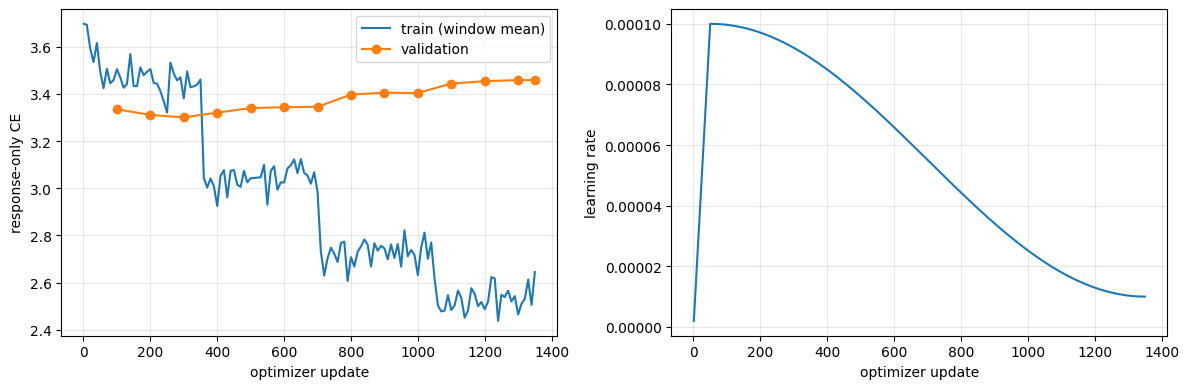

best.pt: update 300 | val loss 3.3007 | non-finite tensors: 0 | size 203 MB
ckpt.pt: update 1350 | val loss 3.3007 | non-finite tensors: 0 | size 610 MB
Selected checkpoint: best.pt = update 300 (lowest validation response loss 3.3007)


In [63]:
# ===================== 11. LOGS + CHECKPOINT INSPECTION =====================
import matplotlib.pyplot as plt
_tl, _vl = OUT_DIR / "train_log.csv", OUT_DIR / "val_log.csv"
if not _vl.exists():
    print(f"No logs in {OUT_DIR} yet. Train first (Section 10).")
else:
    tdf, vdf = pd.read_csv(_tl), pd.read_csv(_vl)
    print("Last training log rows:"); display(tdf.tail(5))
    print("Validation log:"); display(vdf)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(tdf["step"], tdf["train_response_loss"], label="train (window mean)")
    ax[0].plot(vdf["step"], vdf["val_response_loss"], "o-", label="validation")
    ax[0].set_xlabel("optimizer update"); ax[0].set_ylabel("response-only CE"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(tdf["step"], tdf["lr"]); ax[1].set_xlabel("optimizer update"); ax[1].set_ylabel("learning rate"); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.savefig(OUT_DIR / "curves.png", dpi=110); plt.show()

    _best_row = vdf.loc[vdf["val_response_loss"].idxmin()]
    for name in ("best.pt", "ckpt.pt"):
        p = OUT_DIR / name
        if p.exists():
            ck = torch.load(p, map_location="cpu", weights_only=False)
            bad = [k for k, t in ck["model"].items() if t.is_floating_point() and not torch.isfinite(t).all()]
            print(f"{name}: update {ck['step']} | val loss {ck.get('val_response_loss', ck.get('best_val')):.4f} "
                  f"| non-finite tensors: {len(bad)} | size {p.stat().st_size/1e6:.0f} MB")
            if name == "best.pt":
                assert int(ck["step"]) == int(_best_row["step"]), "best.pt is not the lowest-validation update!"
            del ck
    print(f"Selected checkpoint: best.pt = update {int(_best_row['step'])} "
          f"(lowest validation response loss {_best_row['val_response_loss']:.4f})")

## 12. Baseline-versus-fine-tuned evaluation (all available models)

Evaluates every checkpoint that exists, one at a time (never together with training on the GPU):

| model | what it is |
|---|---|
| `baseline_full` | original FULL-tier student, no SFT |
| `sft_dolly_baseline_v3` | FULL-tier student after Dolly SFT (the finished reference run) |
| `baseline_short` | original SHORT-tier student, no SFT |
| `sft_dolly_baseline_short_v1` | SHORT-tier student after Dolly SFT (control, this notebook) |
| `kd_short_T2` | distilled SHORT-tier student, no SFT |
| `sft_dolly_kd_short_T2_v1` | distilled SHORT-tier student after Dolly SFT (**this notebook's main result**) |

For each: (1) **validation response loss** on the identical 592-example Dolly split with the same function (also per category); (2) **generations** for a fixed prompt set covering general QA, open QA, brainstorming, simple instructions, classification, closed QA, information extraction and summarization, with identical prompt format, decoding settings (temperature 0.7, top-k 40, fixed seed) and length limit; (3) a few **Dolly validation examples** next to the human reference; (4) **automatic flags** (heuristics, not proof): `empty`, `no_eos` (hit the length limit), `repetitive` (>30% repeated 3-grams), `template_leak`, `malformed`, `maybe_unrelated`.

The fair pairs are **same tier**: `sft_dolly_kd_short_T2_v1` vs `sft_dolly_baseline_short_v1`. The FULL-tier `sft_dolly_baseline_v3` is shown for context only.

**Must rerun after a runtime reset:** yes, if you want the comparison (no training needed).

In [64]:
# ===================== 12a. EVALUATION SETUP =====================
FIXED_PROMPTS = [   # identical for every model; covers the Dolly task families
    ("general_qa",   "Explain what photosynthesis is in simple terms.", ""),
    ("general_qa",   "Why do we have seasons on Earth?", ""),
    ("open_qa",      "What is the capital of France?", ""),
    ("open_qa",      "Who wrote the play Romeo and Juliet?", ""),
    ("brainstorming","Give me three tips for getting better sleep.", ""),
    ("brainstorming","What should people keep in an emergency kit?", ""),
    ("instruction",  "List the steps to make a cup of tea.", ""),
    ("instruction",  "How do I boil an egg? Give short numbered steps.", ""),
    ("classification","Classify each of the following as a fruit or a vegetable: apple, carrot, banana, spinach.", ""),
    ("classification","Which of these are programming languages: Python, Spanish, Java, French?", ""),
    ("closed_qa",    "According to the text, how long does the river flow?",
                     "The Green River is a small river in the northern valley. It flows for 40 kilometres before joining the lake."),
    ("information_extraction", "Extract the name of the company and the year it was founded from the text.",
                     "Northwind Traders was founded in 1998 in Seattle by two former teachers. It sells outdoor equipment."),
    ("summarization","Summarize the text in one sentence.",
                     "Bees visit flowers to collect nectar and pollen. While doing so they carry pollen from one flower to another, "
                     "which lets plants make seeds. Many fruits and vegetables depend on this. Bee numbers have fallen in recent years "
                     "because of pesticides, disease and loss of wild flowers."),
]
_STOP = set("the a an and or of to in on for is are was were be how what why which who do does did i you it this that "
            "with as at by from give me my your step steps short simple terms explain list tips some".split())

def quality_flags(prompt_text, gen):
    r = gen["text"]; words = re.findall(r"[a-z']+", r.lower())
    flags = []
    if not r.strip(): flags.append("empty")
    if gen.get("hit_limit"): flags.append("no_eos")
    tri = list(zip(words, words[1:], words[2:]))
    if tri and 1 - len(set(tri)) / len(tri) > 0.30: flags.append("repetitive")
    if "###" in r or "Instruction:" in r: flags.append("template_leak")
    if "�" in r: flags.append("malformed")
    pw = {w for w in re.findall(r"[a-z']+", prompt_text.lower()) if len(w) > 3 and w not in _STOP}
    if len(pw) >= 2 and r.strip() and not (pw & set(words)): flags.append("maybe_unrelated")
    return flags

def _pick_val_examples(n):
    by_cat = {}
    for e in sorted(VAL_EXAMPLES, key=lambda e: e["row_id"]):
        by_cat.setdefault(e["category"], e)
    picks = list(by_cat.values())[:n]
    return [ROWS[e["row_id"]] for e in picks]
N_DOLLY_SHOW = 5 if RUN_MODE == "full" else 2
DOLLY_SHOW = _pick_val_examples(N_DOLLY_SHOW)

# every model that exists is evaluated, one at a time, with the same validation examples and prompts
_candidates = [
    ("baseline_full (orig, FULL)",            CHECKPOINT_ROOT / "baseline_full" / "best.pt"),
    ("sft_dolly_baseline_v3 (FULL, SFT)",     REFERENCE_DIR / "best.pt"),
    ("baseline_short (orig, SHORT)",          CHECKPOINT_ROOT / "baseline_short" / "best.pt"),
    ("sft_dolly_baseline_short_v1 (SHORT, SFT)", CHECKPOINT_ROOT / "sft_dolly_baseline_short_v1" / "best.pt"),
    ("kd_short_T2 (distilled, SHORT)",        CHECKPOINT_ROOT / "kd_short_T2" / "best.pt"),
    ("sft_dolly_kd_short_T2_v1 (distilled SHORT, SFT)", CHECKPOINT_ROOT / "sft_dolly_kd_short_T2_v1" / "best.pt"),
]
if RUN_MODE == "smoke":
    _candidates.append((f"SMOKE run ({RUN_NAME})", OUT_DIR / "best.pt"))
EVAL_TARGETS = [(n, p) for n, p in _candidates if p.exists()]
_missing_eval = [n for n, p in _candidates if not p.exists()]
print("Models to evaluate:", [n for n, _ in EVAL_TARGETS])
if _missing_eval:
    print("Not available yet (skipped):", _missing_eval)

Models to evaluate: ['baseline_full (orig, FULL)', 'sft_dolly_baseline_v3 (FULL, SFT)', 'baseline_short (orig, SHORT)', 'sft_dolly_baseline_short_v1 (SHORT, SFT)', 'kd_short_T2 (distilled, SHORT)', 'sft_dolly_kd_short_T2_v1 (distilled SHORT, SFT)']


In [65]:
# ===================== 12b. RUN THE EVALUATION (one model in memory at a time) =====================
EVAL = {}
for name, path in EVAL_TARGETS:
    t0 = time.time()
    m, meta = load_student(path)
    v = evaluate_response_loss(m, VAL_EXAMPLES, ACTIVE["eval_batch"])
    gens = {}
    for kind, instr, ctx in FIXED_PROMPTS:
        p = build_prompt(instr, ctx)
        g = generate_response(m, p, ACTIVE["gen_max_new_tokens"], seed=GEN_SEED)
        g["flags"] = quality_flags(instr + " " + ctx, g); gens[instr] = g
    dolly = {}
    for row in DOLLY_SHOW:
        g = generate_response(m, build_prompt(row["instruction"], row["context"]), ACTIVE["gen_max_new_tokens"], seed=GEN_SEED)
        g["flags"] = quality_flags(row["instruction"] + " " + row["context"], g); dolly[row["row_id"]] = g
    # diagnostic: what happens without stopping at EOS (the failure mode of the first notebooks)
    raw = generate_response(m, build_prompt(FIXED_PROMPTS[4][1]), ACTIVE["gen_max_new_tokens"], stop_at_eos=False, seed=GEN_SEED)
    EVAL[name] = {"path": str(path), "step": meta.get("step"), "val": v, "gens": gens, "dolly": dolly, "no_stop_demo": raw["text"]}
    print(f"{name}: val response loss {v['loss']:.4f} on {v['n_examples']} examples / {v['n_tokens']} tokens "
          f"(checkpoint step {meta.get('step')}, {time.time()-t0:.0f}s)")
    del m; gc.collect()
    if DEVICE == "cuda": torch.cuda.empty_cache()

print("\nValidation response loss per category:")
display(pd.DataFrame({n: r["val"]["per_category"] for n, r in EVAL.items()}).round(3))

baseline_full (orig, FULL): val response loss 3.7424 on 592 examples / 34018 tokens (checkpoint step 20000, 38s)
sft_dolly_baseline_v3 (FULL, SFT): val response loss 3.3473 on 592 examples / 34018 tokens (checkpoint step 300, 16s)
baseline_short (orig, SHORT): val response loss 4.1106 on 592 examples / 34018 tokens (checkpoint step 5000, 30s)
sft_dolly_baseline_short_v1 (SHORT, SFT): val response loss 3.6863 on 592 examples / 34018 tokens (checkpoint step 700, 22s)
kd_short_T2 (distilled, SHORT): val response loss 3.6498 on 592 examples / 34018 tokens (checkpoint step 5000, 28s)
sft_dolly_kd_short_T2_v1 (distilled SHORT, SFT): val response loss 3.3007 on 592 examples / 34018 tokens (checkpoint step 300, 16s)

Validation response loss per category:


,"baseline_full (orig, FULL)","sft_dolly_baseline_v3 (FULL, SFT)","baseline_short (orig, SHORT)","sft_dolly_baseline_short_v1 (SHORT, SFT)","kd_short_T2 (distilled, SHORT)","sft_dolly_kd_short_T2_v1 (distilled SHORT, SFT)"
brainstorming,4.051,3.401,4.421,3.717,3.826,3.396
classification,3.671,2.481,4.112,2.820,3.291,2.359
closed_qa,2.534,2.146,2.921,2.459,2.725,2.159
creative_writing,3.740,3.557,4.041,3.896,3.672,3.552
general_qa,3.778,3.648,4.107,3.970,3.772,3.621
information_extraction,2.608,2.130,3.051,2.482,2.713,2.173
open_qa,3.977,3.720,4.339,4.075,3.889,3.635
summarization,3.192,2.713,3.674,3.142,3.177,2.671


In [66]:
# ===================== 12c. SIDE-BY-SIDE GENERATIONS + FLAGS =====================
import textwrap
def _show(label, g):
    flag = ", ".join(g["flags"]) or "ok"
    end = "EOS" if g["ended_with_eos"] else ("LIMIT" if g["hit_limit"] else "?")
    print(f"  [{label}] ({len(g['new_ids'])} tokens, ended: {end}, flags: {flag})")
    print(textwrap.indent(textwrap.fill(g["text"] or "(empty)", 110), "      "))

print(f"Decoding: temperature {GEN_TEMPERATURE}, top-k {GEN_TOP_K}, seed {GEN_SEED} per prompt, "
      f"max {ACTIVE['gen_max_new_tokens']} new tokens, stop at EOS.\n")
for kind, instr, ctx in FIXED_PROMPTS:
    print("=" * 120); print(f"[{kind}] {instr}" + (f"\n  CONTEXT: {ctx}" if ctx else ""))
    for name in EVAL: _show(name, EVAL[name]["gens"][instr])

print("\n" + "#" * 120 + "\nDOLLY VALIDATION EXAMPLES (with the human reference answer)")
for row in DOLLY_SHOW:
    print("=" * 120); print(f"[{row['category']}] {row['instruction']}")
    if row["context"]: print("  CONTEXT:", textwrap.shorten(row["context"], 300))
    print("  [reference]"); print(textwrap.indent(textwrap.fill(textwrap.shorten(row["response"], 500), 110), "      "))
    for name in EVAL: _show(name, EVAL[name]["dolly"][row["row_id"]])

print("\n" + "#" * 120)
print("DIAGNOSTIC — the same prompt WITHOUT stopping at EOS (⟨EOS⟩ marks id 0; shows whether the model has learned to stop):")
for name in EVAL:
    print(f"  [{name}]"); print(textwrap.indent(textwrap.fill(EVAL[name]["no_stop_demo"], 110), "      "))

_rows = []
for name, r in EVAL.items():
    allg = list(r["gens"].values()) + list(r["dolly"].values())
    _rows.append({"model": name, "val_response_loss": round(r["val"]["loss"], 4),
                  "ended_with_EOS": f"{sum(g['ended_with_eos'] for g in allg)}/{len(allg)}",
                  **{f: sum(f in g["flags"] for g in allg) for f in
                     ["empty", "no_eos", "repetitive", "template_leak", "malformed", "maybe_unrelated"]},
                  "mean_new_tokens": round(float(np.mean([len(g["new_ids"]) for g in allg])), 1)})
QUALITY_TABLE = pd.DataFrame(_rows)
print("\nAutomatic checks (heuristics; read the texts above before drawing conclusions):")
display(QUALITY_TABLE)

Decoding: temperature 0.7, top-k 40, seed 1234 per prompt, max 120 new tokens, stop at EOS.

[general_qa] Explain what photosynthesis is in simple terms.
  [baseline_full (orig, FULL)] (120 tokens, ended: LIMIT, flags: no_eos, repetitive)
      What is the most important thing in life? I want to know more about the meaning of the word. I want to know
      more about the meaning of the word. For me, the word is the key to understanding this word. What are the ways
      we can help others in the world? I want to know more about the meaning of the word. You will learn more about
      the meaning of the word. You will learn more about the meaning of the word. You will learn how to read the
      word in a simple way. You will learn with confidence that
  [sft_dolly_baseline_v3 (FULL, SFT)] (47 tokens, ended: EOS, flags: ok)
      Answering a new plant depends on the type of plant you are in. If the plant has been in use for over 30 years,
      this is the best way to get the best use o

,model,val_response_loss,ended_with_EOS,empty,no_eos,repetitive,template_leak,malformed,maybe_unrelated,mean_new_tokens
0,"baseline_full (orig, FULL)",3.7424,1/18,0,17,17,0,0,2,111.8
1,"sft_dolly_baseline_v3 (FULL, SFT)",3.3473,17/18,0,1,4,0,0,2,48.8
2,"baseline_short (orig, SHORT)",4.1106,0/18,0,18,13,0,0,8,115.4
3,"sft_dolly_baseline_short_v1 (SHORT, SFT)",3.6863,15/18,0,3,6,0,0,3,48.7
4,"kd_short_T2 (distilled, SHORT)",3.6498,4/18,0,14,10,0,0,6,103.6
5,"sft_dolly_kd_short_T2_v1 (distilled SHORT, SFT)",3.3007,14/18,0,4,5,0,0,4,46.1


## 13. Results summary and experiment metadata

Writes `eval/results_summary.json` and `eval/results_summary.md` into the run folder (or, if nothing has been trained yet, into the temporary `tensorix_scratch/eval_only/` folder so no empty run folder is created on Drive) and prints the summary. It also re-fingerprints the baseline file to prove it was not modified.

The **qualitative observations** are left for *you* to write after reading Section 12 — the notebook does not invent them. Fill in `MY_OBSERVATIONS` and rerun this cell.

**Must rerun after a runtime reset:** only after Section 12.

In [67]:
# ===================== 13. RESULTS SUMMARY =====================
MY_OBSERVATIONS = """(write 3-5 sentences after reading Section 12: are answers on topic? do they stop? are they correct?)"""

BASELINE_SHA256_AFTER = sha256_file(START_CKPT)
assert BASELINE_SHA256_AFTER == BASELINE_SHA256_BEFORE, "THE STARTING CHECKPOINT CHANGED — investigate!"
def _ck_meta(path):
    if not path.exists(): return None
    ck = torch.load(path, map_location="cpu", weights_only=False)
    m = {"step": ck.get("step"), "val_response_loss": ck.get("val_response_loss"), "best_val": ck.get("best_val")}
    del ck; return m
def _run_rows(run):
    d = CHECKPOINT_ROOT / run
    if not (d / "val_log.csv").exists(): return None
    v = pd.read_csv(d / "val_log.csv"); b = v.loc[v["val_response_loss"].idxmin()]
    return {"run": run, "updates_done": int(v["step"].max()), "best_update": int(b["step"]),
            "best_val": round(float(b["val_response_loss"]), 4), "final_val": round(float(v.iloc[-1]["val_response_loss"]), 4),
            "overfit": bool(v.iloc[-1]["val_response_loss"] > b["val_response_loss"] + 0.01)}
SFT_TABLE = pd.DataFrame([r for r in (_run_rows(r) for r in
             ("sft_dolly_baseline_v3", "sft_dolly_baseline_short_v1", "sft_dolly_kd_short_T2_v1")) if r])
_best = OUT_DIR / "best.pt"
_best_meta = None
if _best.exists():
    _ck = torch.load(_best, map_location="cpu", weights_only=False)
    _best_meta = {"step": int(_ck["step"]), "val_response_loss": float(_ck["val_response_loss"])}; del _ck

SUMMARY = {
    "created": datetime.datetime.now().isoformat(timespec="seconds"),
    "run_mode": RUN_MODE, "run_name": RUN_NAME,
    "paths": {"start_checkpoint": str(START_CKPT), "run_folder": str(OUT_DIR), "best": str(_best),
              "resumable": str(OUT_DIR / "ckpt.pt")},
    "baseline_unchanged": True, "baseline_sha256": BASELINE_SHA256_BEFORE,
    "selected_checkpoint": _best_meta or "not trained yet",
    "validation_response_loss": {n: round(r["val"]["loss"], 4) for n, r in EVAL.items()},
    "validation_examples": len(VAL_EXAMPLES), "validation_tokens": next(iter(EVAL.values()))["val"]["n_tokens"] if EVAL else None,
    "training_config": RUN_CONFIG["hyperparameters"], "split": {k: v for k, v in SPLIT_INFO.items()},
    "generation": {"temperature": GEN_TEMPERATURE, "top_k": GEN_TOP_K, "seed": GEN_SEED,
                   "max_new_tokens": ACTIVE["gen_max_new_tokens"], "stop_at_eos": True},
    "automatic_quality_checks": QUALITY_TABLE.to_dict(orient="records") if "QUALITY_TABLE" in globals() else None,
    "observations_by_student": MY_OBSERVATIONS.strip(),
    "caveats": ["Lower validation loss does not by itself prove better instruction following; read the generations.",
                "Quality flags are heuristics.",
                "kd_short_T2 and baseline_short are SHORT-tier (5,000 steps); baseline_full is FULL-tier (20,000 steps). "
                "Only same-tier pairs isolate the effect of distillation. The FULL-tier KD checkpoint (kd_full_T2) does not exist yet.",
                "Dolly validation response loss is a different task from the fixed C4/TinyStories evaluation; never compare the two.",
                "Single seed; differences of a few hundredths are within run-to-run noise."],
    "sft_runs": SFT_TABLE.to_dict(orient="records"),
    "reference_run": REFERENCE_RUN, "experiment": EXPERIMENT,
    "environment": VERSIONS,
}
# results go next to the trained run; before any training they go to scratch (never create an empty Drive run folder)
SUMMARY_DIR = (OUT_DIR / "eval") if (OUT_DIR / "ckpt.pt").exists() else (SCRATCH_ROOT / "eval_only" / RUN_NAME)
SUMMARY_DIR.mkdir(parents=True, exist_ok=True)
json.dump(SUMMARY, open(SUMMARY_DIR / "results_summary.json", "w"), indent=2, default=str)

md_lines = [f"# TENSORIX Dolly SFT — distilled vs baseline ({RUN_MODE})", "",
            "## Fine-tuning runs (identical data split, prompt format and settings)", "",
            "| run | start checkpoint | tier | updates | best update | best val loss | final val loss | overfit after best? |",
            "|---|---|---|---|---|---|---|---|"]
_start_of = {"sft_dolly_baseline_v3": ("baseline_full", "FULL"), "sft_dolly_baseline_short_v1": ("baseline_short", "SHORT"),
             "sft_dolly_kd_short_T2_v1": ("kd_short_T2 (KD T=2)", "SHORT")}
for _, r in SFT_TABLE.iterrows():
    md_lines.append(f"| `{r['run']}` | `{_start_of[r['run']][0]}` | {_start_of[r['run']][1]} | {r['updates_done']} | "
                    f"{r['best_update']} | {r['best_val']} | {r['final_val']} | {'yes' if r['overfit'] else 'no'} |")
md_lines += ["", "## All models on the same Dolly validation split", "",
            f"Validation: {len(VAL_EXAMPLES)} Dolly examples, response-only token-weighted CE (NOT comparable with C4/TinyStories losses). "
            f"Decoding: temperature {GEN_TEMPERATURE}, top-k {GEN_TOP_K}, seed {GEN_SEED}, max {ACTIVE['gen_max_new_tokens']} new tokens, "
            f"{len(FIXED_PROMPTS)} fixed prompts + {len(DOLLY_SHOW)} Dolly validation prompts.", "",
            "| model | val response loss | ended with EOS | no_eos | repetitive | maybe_unrelated |", "|---|---|---|---|---|---|"]
if "QUALITY_TABLE" in globals():
    for _, r in QUALITY_TABLE.iterrows():
        md_lines.append(f"| {r['model']} | {r['val_response_loss']} | {r['ended_with_EOS']} | {r['no_eos']} | {r['repetitive']} | {r['maybe_unrelated']} |")
md_lines += ["", f"Training config (all SFT runs): `{json.dumps(RUN_CONFIG['hyperparameters'])}`, seed {SEED}, "
             f"split {REF_SPLIT['train_kept']} train / {REF_SPLIT['val_kept']} val, {REF_SPLIT['dropped']} dropped (>{MAX_LENGTH} tokens).", "",
             f"Checkpoints: `{CHECKPOINT_ROOT}/<run>/best.pt` (selected) and `ckpt.pt` (resumable).", "",
             "## Observations (written by the student)", MY_OBSERVATIONS.strip(), "",
             "## Caveats", *[f"* {c}" for c in SUMMARY["caveats"]]]
open(SUMMARY_DIR / "results_summary.md", "w").write("\n".join(md_lines))
print("\n".join(md_lines))
print(f"\nSaved: {SUMMARY_DIR / 'results_summary.json'} and .md")
# a copy at the top level / results/RESULTS.md (only when something was trained for real)
if RUN_MODE == "full":
    (DRIVE_ROOT / "results" / "sft").mkdir(parents=True, exist_ok=True)
    open(DRIVE_ROOT / "results" / "sft" / "sft_comparison.md", "w").write("\n".join(md_lines))
    json.dump(SUMMARY, open(DRIVE_ROOT / "results" / "sft" / "sft_comparison.json", "w"), indent=2, default=str)
    print(f"Also saved: {DRIVE_ROOT / 'results' / 'sft' / 'sft_comparison.md'}")

# TENSORIX Dolly SFT — distilled vs baseline (full)

## Fine-tuning runs (identical data split, prompt format and settings)

| run | start checkpoint | tier | updates | best update | best val loss | final val loss | overfit after best? |
|---|---|---|---|---|---|---|---|
| `sft_dolly_baseline_v3` | `baseline_full` | FULL | 1350 | 300 | 3.3473 | 3.4733 | yes |
| `sft_dolly_baseline_short_v1` | `baseline_short` | SHORT | 1350 | 700 | 3.6863 | 3.7592 | yes |
| `sft_dolly_kd_short_T2_v1` | `kd_short_T2 (KD T=2)` | SHORT | 1350 | 300 | 3.3007 | 3.4586 | yes |

## All models on the same Dolly validation split

Validation: 592 Dolly examples, response-only token-weighted CE (NOT comparable with C4/TinyStories losses). Decoding: temperature 0.7, top-k 40, seed 1234, max 120 new tokens, 13 fixed prompts + 5 Dolly validation prompts.

| model | val response loss | ended with EOS | no_eos | repetitive | maybe_unrelated |
|---|---|---|---|---|---|
| baseline_full (orig, FULL) | 3.7424 | 1/18 | 17 

### 13b. Optional: post-SFT C4 / TinyStories scores with the repo's `evaluate.py`

Separate from the Dolly loss above. This runs `src/evaluate.py` (fixed 1,024 windows per domain, seed 0 — the project's pretraining metric) on the SFT checkpoints. Needs `val_c4.bin` and `val_ts.bin` from `MyDrive/tensorix/v2/data/` (about 10 MB each; `train.bin` is **not** copied). Set `RUN_EVALUATE_PY = True` to run it. GPU recommended; skip in smoke mode.

In [68]:
# ===================== 13b. OPTIONAL evaluate.py (C4 / TinyStories) =====================
RUN_EVALUATE_PY = False
if RUN_EVALUATE_PY and RUN_MODE == "full":
    import shutil
    _local_data = WORK_ROOT / "data_val_only"; _local_data.mkdir(exist_ok=True)
    for _f in ("val_c4.bin", "val_ts.bin"):
        if not (_local_data / _f).exists():
            if not (DATA_DIR / _f).exists():
                raise FileNotFoundError(f"{DATA_DIR / _f} not found")
            shutil.copy(DATA_DIR / _f, _local_data / _f)
    _eval_out = DRIVE_ROOT / "results" / "sft" / "eval_c4_ts"; _eval_out.mkdir(parents=True, exist_ok=True)
    for _run in ("sft_dolly_baseline_v3", "sft_dolly_baseline_short_v1", "sft_dolly_kd_short_T2_v1"):
        _ck = CHECKPOINT_ROOT / _run / "best.pt"
        if not _ck.exists():
            print("skip (missing):", _run); continue
        if (_eval_out / f"{_run}.json").exists():
            print("already done:", _run); continue
        r = subprocess.run([sys.executable, str(REPO_DIR / "src" / "evaluate.py"), "--data_dir", str(_local_data),
                            "--ckpt", str(_ck), "--name", _run, "--out_dir", str(_eval_out)], capture_output=True, text=True)
        print(r.stdout[-1500:], r.stderr[-800:] if r.returncode else "")
    _rows = []
    for _j in sorted(_eval_out.glob("*.json")):
        _d = json.load(open(_j)); _rows.append({k: _d.get(k) for k in ("name", "step", "val_c4_loss", "val_c4_ppl", "val_ts_loss", "val_ts_ppl")})
    display(pd.DataFrame(_rows))
    print("Pretraining references from the README: baseline_short C4 4.3964 / TS 1.8342; kd_short_T2 4.1207 / 1.8425; baseline_full 4.085 / 1.619")
else:
    print("Skipped (RUN_EVALUATE_PY is False or smoke mode).")

Skipped (RUN_EVALUATE_PY is False or smoke mode).


## 14. Troubleshooting and resume instructions

### Colab disconnected / runtime reset during training
1. Reconnect (with a GPU if possible). Do **not** change `RUN_NAME` or any setting in Section 2.
2. Make sure `RUN_MODE = "full"` and `START_TRAINING = True`.
3. Run Sections 2 → 10 in order. Section 10 prints `RESUMED … at update N` and continues from the last save (at most `save_every` = 100 updates are lost).
4. If it says the settings differ, either put the old values back or start a new run with a new `RUN_NAME`. Nothing is overwritten.

### "Cannot connect to GPU backend" / GPU quota exhausted
* Click **Close**, not "Connect without GPU" for the full run. Your progress is safe on Drive in `ckpt.pt`.
* Wait (often until the next day) and resume as above. The smoke test and Sections 11–13 can run on CPU.
* Disconnect the runtime when you finish (Runtime → Disconnect and delete runtime) to save quota.

### CUDA out of memory
Not expected: the baseline run used `micro_batch=16, grad_accum=2` on a T4. If it happens, restart the runtime (another process may hold memory). Do **not** change the batch settings for this experiment, because Section 3 requires them to match the baseline run.

### Training stops with "updates in a row were skipped"
The fp16 run produced non-finite gradients repeatedly. Start a new run with `lr=5e-5`. A handful of skipped updates at the very start is normal (the gradient scaler calibrating) and does not move the LR schedule.

### The answers are still poor
Expected to some degree: these are 51M SHORT-tier models. Report what you see. Do not tune settings for the KD run alone; any change would have to be applied to a new baseline run as well.

### "Settings differ from sft_dolly_baseline_v3" / "Split differs"
Do **not** change the settings to make it pass: the point of this notebook is to reproduce the baseline run exactly. If the split differs, the Dolly dataset on the Hub or the tokenizer changed; stop and tell the team.

### Running the control experiment
Set `EXPERIMENT = "baseline_short"` and rerun from Section 2. Nothing else changes.

### Running the FULL-tier distilled model later
When `kd_full_T2` exists, add an entry to `EXPERIMENTS` (`starting_run="kd_full_T2"`, `run_name="sft_dolly_kd_full_v1"`), pick it, and remove nothing else. Its fair partner is `sft_dolly_baseline_v3`.

### Where are my files?
`MyDrive/tensorix/v2/checkpoints/<RUN_NAME>/` — `best.pt` (evaluate this), `ckpt.pt` (resume), `train_log.csv`, `val_log.csv`, `curves.png`, `run_config.json`, `split.json`, `environment.json`, `eval/results_summary.{json,md}`.

### Loading the fine-tuned model elsewhere
```python
import sys; sys.path.insert(0, "/content/tensorix-kd-slm/src")
from model import load_checkpoint
model, ck = load_checkpoint("/content/drive/MyDrive/tensorix/v2/checkpoints/sft_dolly_kd_short_T2_v1/best.pt", device="cuda")
# generate with the prompt format of Section 7 and stop at EOS (id 0), e.g. by reusing generate_response()
```